In [1]:
!pip install -q \
albumentations \
opencv-python-headless \
timm \
grad-cam \
scikit-learn \
seaborn \
torchxrayvision

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os
import cv2
import json
import math
import torch
import shutil
import random
import zipfile
import numpy as np
import pandas as pd
import torch.nn as nn
from pathlib import Path
from tqdm.auto import tqdm
import albumentations as A
import torch.optim as optim
import torchxrayvision as xrv
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score, f1_score,
    roc_curve, confusion_matrix,
    roc_auc_score,
    average_precision_score,
)
from google.colab import drive
import matplotlib.pyplot as plt
from torch.amp import autocast, GradScaler
from torch.utils.data import Dataset, DataLoader

In [3]:
from google.colab import drive

In [4]:
drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
!ls /content/drive/MyDrive/AI_Research/Model_Results/SaliencyRun/xrv_pipeline_nb/grad_vanilla_npy_25/seed_1000 | wc -l

In [5]:
#change

CONFIG = {
    "dataset_root": "/content/rsna-pneumonia-dataset-npy",
    "model_name": "DenseNet121",
    "save_dir": "/content/drive/MyDrive/AI_Research/Model_Results/SaliencyRun", # CHANGE
}

os.makedirs(CONFIG["save_dir"], exist_ok=True)

print(f"Directory made: {CONFIG['save_dir']}")

Directory made: /content/drive/MyDrive/AI_Research/Model_Results/SaliencyRun


In [6]:
ZIP_PATH = "/content/drive/MyDrive/AI_Research/rsna-pneumonia-dataset-npy.zip"
EXTRACT_DIR = "/content/rsna-pneumonia-dataset-npy"

if not os.path.exists(EXTRACT_DIR):
    with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
        zip_ref.extractall("/content")

print("Dataset extracted")
DRIVE_ROOT = "/content/drive/MyDrive/AI_Research"

for fname in [
    "test_split.csv",
    "train_split.csv",
    "val_split.csv",
    "stage_2_train_labels.csv"
]:
    src = os.path.join(DRIVE_ROOT, fname)
    dst = os.path.join(EXTRACT_DIR, fname)

    shutil.copy2(src, dst)
    print(f"Copied {fname}")

Dataset extracted
Copied test_split.csv
Copied train_split.csv
Copied val_split.csv
Copied stage_2_train_labels.csv


In [7]:
SAVE_DIR = CONFIG["save_dir"]

os.makedirs(SAVE_DIR, exist_ok=True)

os.makedirs(
    os.path.join(SAVE_DIR, "gradcam"),
    exist_ok=True
)

os.makedirs(
    os.path.join(SAVE_DIR, "misclassified"),
    exist_ok=True
)

print(SAVE_DIR)

/content/drive/MyDrive/AI_Research/Model_Results/SaliencyRun


In [ ]:
train_ds = pd.read_csv(
    "/content/rsna-pneumonia-dataset-npy/train_split.csv"
)

val_ds = pd.read_csv(
    "/content/rsna-pneumonia-dataset-npy/val_split.csv"
)

test_ds = pd.read_csv(
    "/content/rsna-pneumonia-dataset-npy/test_split.csv"
)

print(len(train_ds))
print(len(val_ds))
print(len(test_ds))

In [10]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

#change

NPY_MAP_PATH = "/content/drive/MyDrive/AI_Research/npy_map.json"
IMAGES_DIR = "/content/rsna-pneumonia-dataset-npy/images"

if os.path.exists(NPY_MAP_PATH):
    print("Loading existing NPY map.")

    with open(NPY_MAP_PATH, "r") as f:
        npy_map = json.load(f)

else:
    print("Building NPY map.")

    npy_map = {
        f.stem: str(f)
        for f in Path(IMAGES_DIR).rglob("*.npy")
    }

    os.makedirs("/content/drive/MyDrive/AI_Research", exist_ok=True)

    with open(NPY_MAP_PATH, "w") as f:
        json.dump(npy_map, f)

print(f"Loaded {len(npy_map):,} paths")

sample_patient = next(iter(npy_map))
print(sample_patient)
print(npy_map[sample_patient])

Loading existing NPY map.
Loaded 26,684 paths
6bf02e28-807b-4020-a18a-3d34fed0d3aa
/content/rsna-pneumonia-dataset-npy/images/shard_009/6bf02e28-807b-4020-a18a-3d34fed0d3aa.npy


In [ ]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import random
import numpy as np
import torch
import cv2

def set_determinism(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.use_deterministic_algorithms(True)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def seed_worker(worker_id):
    cv2.setNumThreads(0)
    cv2.ocl.setUseOpenCL(False)
    worker_seed = torch.initial_seed() % 2**32
    np.random.seed(worker_seed)
    random.seed(worker_seed)

def make_generator(seed):
    g = torch.Generator()
    g.manual_seed(seed)
    return g

In [ ]:
def collate_fn(batch):

    images = torch.stack(
        [x["image"] for x in batch]
    )
    labels = torch.stack(
        [x["label"] for x in batch]
    )
    bboxes = torch.stack(
        [x["bbox"] for x in batch]
    )
    patient_ids = [
        x["patient_id"]
        for x in batch
    ]
    return {
        "images": images,
        "labels": labels,
        "bboxes": bboxes,
        "patient_ids": patient_ids
    }

In [ ]:
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(device)

In [ ]:
cv2.setNumThreads(0)
cv2.ocl.setUseOpenCL(False)

def worker_init_fn(worker_id):
    import cv2
    cv2.setNumThreads(0)
    cv2.ocl.setUseOpenCL(False)

In [8]:
HPARAMS2 = {
    "run_name": "frozen_xrv",
    "img_size": 224,
    "epochs": 25,
    "batch_size": 128,
    "initial_lr": 0.0004448862857672661,
    "weight_decay": 1.3560236266648827e-05,
    "dropout": 0.3366734543720239,
    "cosine_tmax": 25,
    "seeds": [42, 739, 2026, 7, 13, 21, 99, 123, 256, 314, 500, 777, 1000, 1234, 2024, 2025, 3407, 4096, 5555, 8080, 9999],
    "xrv_weights": "densenet121-res224-mimic_nb",
}

XRV_SAVE_DIR = os.path.join(SAVE_DIR, "xrv_pipeline_nb") #change to ch vs nb
os.makedirs(XRV_SAVE_DIR, exist_ok=True)
print(XRV_SAVE_DIR)

/content/drive/MyDrive/AI_Research/Model_Results/SaliencyRun/xrv_pipeline_nb


In [ ]:
HPARAMS2 = {
    "run_name": "frozen_xrv",
    "img_size": 224,
    "epochs": 25,
    "batch_size": 128,
    "initial_lr": 0.0004448862857672661,
    "weight_decay": 1.3560236266648827e-05,
    "dropout": 0.3366734543720239,
    "cosine_tmax": 25,
    "seeds": [9999],
    "xrv_weights": "densenet121-res224-mimic_nb",
}

XRV_SAVE_DIR = os.path.join(SAVE_DIR, "xrv_pipeline_nb") #change to ch vs nb
os.makedirs(XRV_SAVE_DIR, exist_ok=True)
print(XRV_SAVE_DIR)

run discussions f1 - f4

1. BETWEEN-SEED VARIANCE
  observed SD of per-seed means : 0.0243
  permutation null              : 0.0050 (95th pct 0.0064)
  permutation p                 : 0.0010
  one-way ANOVA                 : F=5.95, p=5.442e-16

  scoring the centre-Gaussian baseline per image...
    200/601
    400/601
    600/601

2. VERSUS THE CENTRE-GAUSSIAN BASELINE
  baseline mean AUPRC        : 0.2810
  seeds scoring below it     : 10/21
  significantly worse (p<.05): 10/21
  significantly better       : 5/21
  mean margin over baseline  : +0.0091
  seed spread / margin       : 2.7x

3. LOCALIZATION vs CLASSIFICATION (per seed, n=21)
  ROC-AUC  r=-0.028 (p=0.905, 95% CI [-0.38, +0.42])   rho=+0.049 (p=0.832)
  PR-AUC   r=-0.033 (p=0.888, 95% CI [-0.41, +0.46])   rho=-0.105 (p=0.650)

4. PER-IMAGE SD ACROSS SEEDS
  median 0.0968  95% CI [0.0903, 0.1024]
  fraction of images with SD > 0.01 : 89.2%
  fraction of images with SD > 0.02 : 85.7%
  fraction of images with SD > 0.07 : 65.4%
  fraction of images 

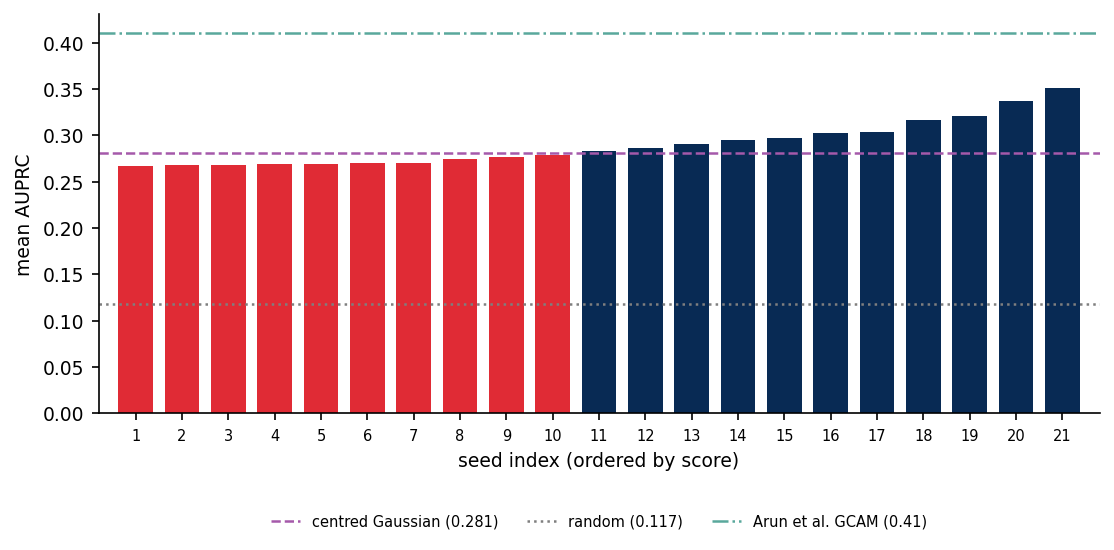

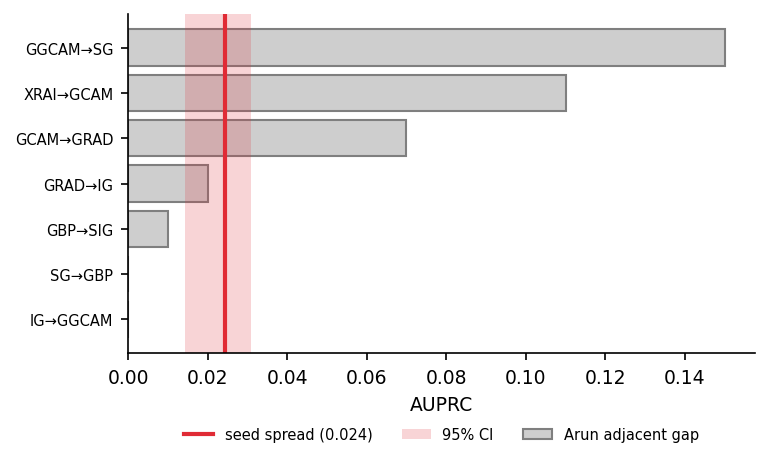

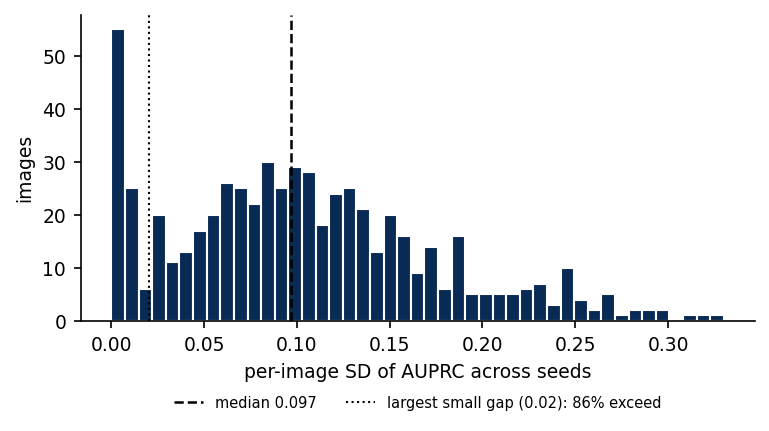

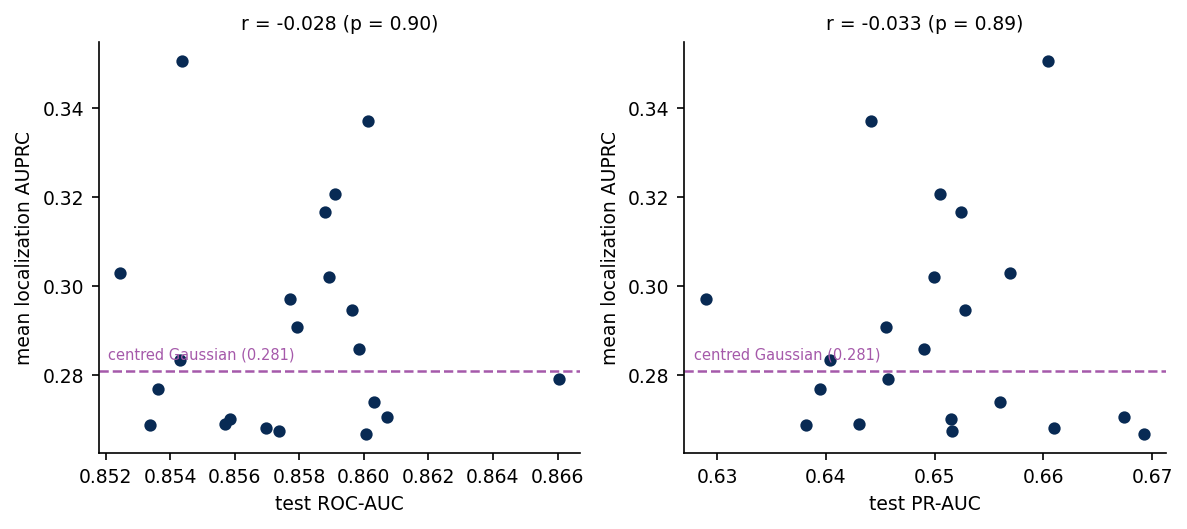


 seed  auprc_mean  pointing_hit  test_roc_auc  test_pr_auc  best_epoch
    7      0.3372        0.4309        0.8601       0.6441           7
   13      0.3208        0.4509        0.8591       0.6505           4
   21      0.2674        0.3045        0.8574       0.6516           4
   42      0.2970        0.3744        0.8577       0.6290           5
   99      0.3020        0.3910        0.8589       0.6499           4
  123      0.3508        0.4975        0.8544       0.6605           7
  256      0.2791        0.3394        0.8660       0.6457           6
  314      0.2833        0.3594        0.8543       0.6403           5
  500      0.2740        0.3261        0.8603       0.6560           5
  739      0.2687        0.3028        0.8534       0.6382           8
  777      0.2946        0.3844        0.8596       0.6528           5
 1000      0.2700        0.3478        0.8558       0.6515           6
 1234      0.3030        0.4077        0.8525       0.6569           4
 2024

In [9]:
import os, json
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.metrics import average_precision_score

AGG      = os.path.join(XRV_SAVE_DIR, "gradcam_metrics_25_withGBP", "_aggregate")
OUT      = os.path.join(XRV_SAVE_DIR, "paper_outputs")
os.makedirs(OUT, exist_ok=True)

SCORE_SIZE = 1024
N_BOOT     = 1000
rng = np.random.default_rng(42)

plt.rcParams.update({"font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 150})

scores  = pd.read_csv(os.path.join(AGG, "per_image_per_seed_scores.csv"))
per_seed = pd.read_csv(os.path.join(AGG, "per_seed_summary.csv"))
per_img  = pd.read_csv(os.path.join(AGG, "per_image_variance.csv"))
equiv    = pd.read_csv(os.path.join(AGG, "model_equivalence.csv"))
summ     = json.load(open(os.path.join(AGG, "summary.json")))

labels_df = pd.read_csv("/content/rsna-pneumonia-dataset-npy/stage_2_train_labels.csv")

SPREAD   = summ["primary_auprc"]["spread_sd_of_per_seed_mean"]
CI       = summ["primary_auprc"]["bootstrap_ci_95"]
GAPS     = summ["arun_gaps"]
RANDOM_B = summ["baseline_random"]
CENTRE_B = summ["baseline_centre_gaussian"]

R = {}   # everything reportable ends up here

wide = scores.pivot(index="patientId", columns="seed", values="auprc").dropna()
obs = wide.mean(axis=0).std(ddof=1)

null = np.empty(N_BOOT)
vals = wide.to_numpy()
for b in range(N_BOOT):
    permuted = np.apply_along_axis(rng.permutation, 1, vals)   # shuffle within image
    null[b] = permuted.mean(axis=0).std(ddof=1)
p_perm = (np.sum(null >= obs) + 1) / (N_BOOT + 1)

f_stat, p_anova = stats.f_oneway(*[wide[c].values for c in wide.columns])

R["between_seed_variance"] = {
    "observed_sd": float(obs),
    "null_sd_mean": float(null.mean()),
    "null_sd_95th": float(np.percentile(null, 95)),
    "permutation_p": float(p_perm),
    "anova_F": float(f_stat), "anova_p": float(p_anova),
    "n_permutations": N_BOOT,
}
print("=" * 72)
print("1. BETWEEN-SEED VARIANCE")
print("=" * 72)
print(f"  observed SD of per-seed means : {obs:.4f}")
print(f"  permutation null              : {null.mean():.4f} "
      f"(95th pct {np.percentile(null,95):.4f})")
print(f"  permutation p                 : {p_perm:.4f}")
print(f"  one-way ANOVA                 : F={f_stat:.2f}, p={p_anova:.3e}")


def box_mask(pid):
    r = labels_df[(labels_df.patientId == pid) & (labels_df.Target == 1)]
    r = r.dropna(subset=["x", "y", "width", "height"])
    if r.empty:
        return None
    m = np.zeros((SCORE_SIZE, SCORE_SIZE), np.uint8)
    for _, b in r.iterrows():
        x0, y0 = int(b.x), int(b.y)
        x1, y1 = int(b.x + b.width), int(b.y + b.height)
        m[max(y0, 0):min(y1, SCORE_SIZE), max(x0, 0):min(x1, SCORE_SIZE)] = 1
    return m if m.sum() else None


yy, xx = np.mgrid[0:SCORE_SIZE, 0:SCORE_SIZE]
c = SCORE_SIZE / 2
centre_map = np.exp(-((xx - c) ** 2 + (yy - c) ** 2) /
                    (2 * (SCORE_SIZE / 5) ** 2)).astype(np.float32).ravel()

print("\n  scoring the centre-Gaussian baseline per image...")
centre_by_pid = {}
for i, pid in enumerate(wide.index, 1):
    gt = box_mask(pid)
    if gt is not None:
        centre_by_pid[pid] = float(average_precision_score(gt.ravel(), centre_map))
    if i % 200 == 0:
        print(f"    {i}/{len(wide)}")

cb = pd.Series(centre_by_pid)
rows = []
for seed in wide.columns:
    d = wide[seed] - cb.reindex(wide.index)
    w_stat, w_p = stats.wilcoxon(wide[seed], cb.reindex(wide.index))
    rows.append({"seed": seed, "auprc": wide[seed].mean(),
                 "diff_vs_centre": d.mean(), "wilcoxon_p": w_p,
                 "beats_centre": bool(d.mean() > 0)})
cmp_centre = pd.DataFrame(rows)
cmp_centre.to_csv(os.path.join(OUT, "vs_centre_baseline.csv"), index=False)

n_below = int((~cmp_centre.beats_centre).sum())
n_sig_worse = int(((cmp_centre.diff_vs_centre < 0) & (cmp_centre.wilcoxon_p < .05)).sum())
n_sig_better = int(((cmp_centre.diff_vs_centre > 0) & (cmp_centre.wilcoxon_p < .05)).sum())

R["vs_centre_baseline"] = {
    "baseline_auprc": float(cb.mean()),
    "seeds_below": n_below, "seeds_significantly_worse": n_sig_worse,
    "seeds_significantly_better": n_sig_better,
    "mean_margin": float(per_seed.auprc_mean.mean() - cb.mean()),
    "spread_over_margin": float(SPREAD / (per_seed.auprc_mean.mean() - cb.mean())),
}
print("\n" + "=" * 72)
print("2. VERSUS THE CENTRE-GAUSSIAN BASELINE")
print("=" * 72)
print(f"  baseline mean AUPRC        : {cb.mean():.4f}")
print(f"  seeds scoring below it     : {n_below}/21")
print(f"  significantly worse (p<.05): {n_sig_worse}/21")
print(f"  significantly better       : {n_sig_better}/21")
print(f"  mean margin over baseline  : {R['vs_centre_baseline']['mean_margin']:+.4f}")
print(f"  seed spread / margin       : {R['vs_centre_baseline']['spread_over_margin']:.1f}x")


# localization vs classification
merged = per_seed.merge(equiv, on="seed")
R["loc_vs_class"] = {}
print("\n" + "=" * 72)
print("3. LOCALIZATION vs CLASSIFICATION (per seed, n=21)")
print("=" * 72)
for col, lab in [("test_roc_auc", "ROC-AUC"), ("test_pr_auc", "PR-AUC")]:
    r_p, p_p = stats.pearsonr(merged.auprc_mean, merged[col])
    r_s, p_s = stats.spearmanr(merged.auprc_mean, merged[col])
    lo, hi = np.percentile([
        stats.pearsonr(*merged.iloc[rng.choice(len(merged), len(merged), True)]
                       [["auprc_mean", col]].values.T)[0]
        for _ in range(N_BOOT)], [2.5, 97.5])
    R["loc_vs_class"][lab] = {"pearson_r": float(r_p), "pearson_p": float(p_p),
                              "pearson_ci95": [float(lo), float(hi)],
                              "spearman_rho": float(r_s), "spearman_p": float(p_s)}
    print(f"  {lab:<8} r={r_p:+.3f} (p={p_p:.3f}, 95% CI [{lo:+.2f}, {hi:+.2f}])   "
          f"rho={r_s:+.3f} (p={p_s:.3f})")


# bootstrap per sd
med_boot = np.array([np.median(rng.choice(per_img["std"].values,
                                          len(per_img), True))
                     for _ in range(N_BOOT)])
lo_m, hi_m = np.percentile(med_boot, [2.5, 97.5])
frac_above = {g: float((per_img["std"] > g).mean()) for g in (0.01, 0.02, 0.07, 0.11)}

R["per_image_sd"] = {
    "median": float(per_img["std"].median()),
    "median_ci95": [float(lo_m), float(hi_m)],
    "iqr": [float(per_img["std"].quantile(.25)), float(per_img["std"].quantile(.75))],
    "fraction_exceeding_gap": frac_above,
}
print("\n" + "=" * 72)
print("4. PER-IMAGE SD ACROSS SEEDS")
print("=" * 72)
print(f"  median {per_img['std'].median():.4f}  95% CI [{lo_m:.4f}, {hi_m:.4f}]")
for g, f in frac_above.items():
    print(f"  fraction of images with SD > {g:.2f} : {f:.1%}")


# robustness
trimmed = per_seed[per_seed.auprc_mean < per_seed.auprc_mean.max()]
R["robustness_drop_max_seed"] = {
    "dropped_seed": int(per_seed.loc[per_seed.auprc_mean.idxmax(), "seed"]),
    "sd_without": float(trimmed.auprc_mean.std(ddof=1)),
    "gaps_still_matched": int(sum(trimmed.auprc_mean.std(ddof=1) >= g
                                  for g in GAPS.values())),
    "skew": float(per_seed.auprc_mean.skew()),
}
print("\n  robustness: dropping seed "
      f"{R['robustness_drop_max_seed']['dropped_seed']} -> SD "
      f"{R['robustness_drop_max_seed']['sd_without']:.4f}, still "
      f"{R['robustness_drop_max_seed']['gaps_still_matched']}/7 gaps")

with open(os.path.join(OUT, "stats.json"), "w") as f:
    json.dump(R, f, indent=4)


# figs
ps = per_seed.sort_values("auprc_mean").reset_index(drop=True)

# F1: per-seed AUPRC with both baselines  (paper Figure 2)
fig, ax = plt.subplots(figsize=(7.5, 3.8))
colors = ["#e02b35" if v < CENTRE_B else "#082a54" for v in ps.auprc_mean]
ax.bar(range(len(ps)), ps.auprc_mean, color=colors, width=.75)
ax.axhline(CENTRE_B, color="#a559aa", ls="--", lw=1.2,
           label=f"centred Gaussian ({CENTRE_B:.3f})")
ax.axhline(RANDOM_B, color="#7f7f7f", ls=":", lw=1.2,
           label=f"random ({RANDOM_B:.3f})")
ax.axhline(0.41, color="#59a89c", ls="-.", lw=1.2, label="Arun et al. GCAM (0.41)")
ax.set_xticks(range(len(ps)))
ax.set_xticklabels(range(1, len(ps) + 1), fontsize=7)
ax.set_xlabel("seed index (ordered by score)")
ax.set_ylabel("mean AUPRC")
ax.set_xlim(-0.8, len(ps) - 0.2)
ax.legend(fontsize=7, frameon=False, ncol=3,
          loc="upper center", bbox_to_anchor=(0.5, -0.22))
plt.tight_layout()
plt.savefig(os.path.join(OUT, "F1_per_seed_auprc.pdf"), bbox_inches="tight")
plt.show()

# F2: spread vs gaps
fig, ax = plt.subplots(figsize=(5.2, 3.2))
names, vals = list(GAPS.keys()), list(GAPS.values())
order = np.argsort(vals)
ax.barh(range(len(vals)), [vals[i] for i in order], color="#cecece",
        edgecolor="#7f7f7f", label="Arun adjacent gap")
ax.axvline(SPREAD, color="#e02b35", lw=2, label=f"seed spread ({SPREAD:.3f})")
ax.axvspan(CI[0], CI[1], color="#e02b35", alpha=.2, lw=0, label="95% CI")
ax.set_yticks(range(len(vals)))
ax.set_yticklabels([names[i].replace("->", "\u2192") for i in order], fontsize=7)
ax.set_xlabel("AUPRC")
ax.legend(fontsize=7, frameon=False, ncol=3,
          loc="upper center", bbox_to_anchor=(0.5, -0.18))
plt.tight_layout(); plt.savefig(os.path.join(OUT, "F2_spread_vs_gaps.pdf"),
                                bbox_inches="tight"); plt.show()

# F3: per-image SD
fig, ax = plt.subplots(figsize=(5.2, 3.0))
ax.hist(per_img["std"], bins=45, color="#082a54", edgecolor="white", lw=.3)
ax.axvline(per_img["std"].median(), color="black", ls="--", lw=1.2,
           label=f"median {per_img['std'].median():.3f}")
ax.axvline(0.02, color="k", ls=":", lw=1,
           label=f"largest small gap (0.02): {frac_above[0.02]:.0%} exceed")
ax.set_xlabel("per-image SD of AUPRC across seeds"); ax.set_ylabel("images")
ax.legend(fontsize=7, frameon=False, ncol=2,
          loc="upper center", bbox_to_anchor=(0.5, -0.20))
plt.tight_layout(); plt.savefig(os.path.join(OUT, "F3_per_image_sd.pdf"),
                                bbox_inches="tight"); plt.show()

# F4: localization vs classification  (paper Figure 3)
fig, ax = plt.subplots(1, 2, figsize=(8, 3.6))
for a, col, lab in [(ax[0], "test_roc_auc", "test ROC-AUC"),
                    (ax[1], "test_pr_auc", "test PR-AUC")]:
    a.scatter(merged[col], merged.auprc_mean, s=24, color="#082a54", zorder=3)
    a.axhline(CENTRE_B, color="#a559aa", ls="--", lw=1.2)
    a.annotate(f"centred Gaussian ({CENTRE_B:.3f})",
               xy=(0.02, CENTRE_B), xycoords=("axes fraction", "data"),
               xytext=(0, 4), textcoords="offset points",
               color="#a559aa", fontsize=7, va="bottom")
    st = R["loc_vs_class"]["ROC-AUC" if "roc" in col else "PR-AUC"]
    a.set_xlabel(lab)
    a.set_ylabel("mean localization AUPRC")
    a.set_title(f"r = {st['pearson_r']:+.3f} (p = {st['pearson_p']:.2f})",
                fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(OUT, "F4_loc_vs_class.pdf"), bbox_inches="tight")
plt.show()

# T1
t1 = (per_seed[["seed", "auprc_mean", "pointing_hit"]]
      .merge(equiv[["seed", "test_roc_auc", "test_pr_auc", "best_epoch"]], on="seed")
      .sort_values("seed").round(4))
t1.to_csv(os.path.join(OUT, "T1_per_seed.csv"), index=False)
print("\n" + t1.to_string(index=False))
print(f"\nsaved to {OUT}")

additional f5 test qualitative

median per-image SD across 601 images: 0.0968



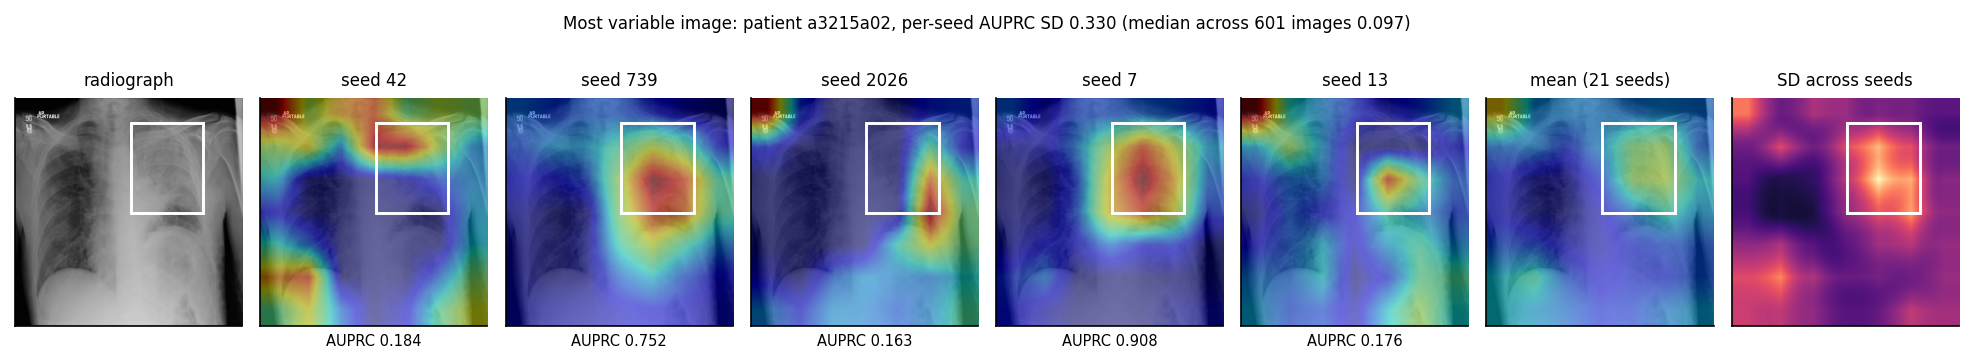

[worst_sd] a3215a02-302a-40c7-ab0e-e1159cce77f6  SD 0.3301  AUPRC 0.079-0.935
  saved -> /content/drive/MyDrive/AI_Research/Model_Results/SaliencyRun/xrv_pipeline_nb/images_output/worst_sd.pdf
  Grad-CAM maps for patient a3215a02-302a-40c7-ab0e-e1159cce77f6, most variable image among the 601 box-bearing test images by per-seed AUPRC standard deviation (0.330; median across images 0.097). Five of the 21 seeds are shown with their per-image AUPRC; the mean and standard deviation panels use all 21 seeds. Per-seed AUPRC for this image ranges 0.079 to 0.935. Ground-truth boxes in white.



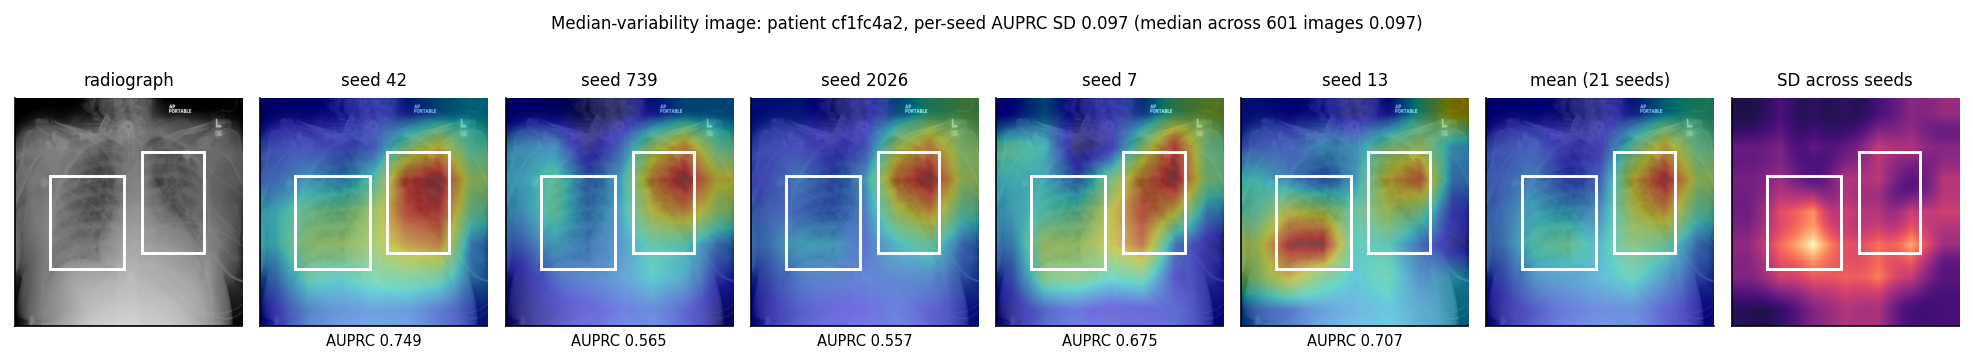

[median_sd] cf1fc4a2-aa47-4662-9118-9da725a17e84  SD 0.0968  AUPRC 0.423-0.801
  saved -> /content/drive/MyDrive/AI_Research/Model_Results/SaliencyRun/xrv_pipeline_nb/images_output/median_sd.pdf
  Grad-CAM maps for patient cf1fc4a2-aa47-4662-9118-9da725a17e84, median-variability image among the 601 box-bearing test images by per-seed AUPRC standard deviation (0.097; median across images 0.097). Five of the 21 seeds are shown with their per-image AUPRC; the mean and standard deviation panels use all 21 seeds. Per-seed AUPRC for this image ranges 0.423 to 0.801. Ground-truth boxes in white.



In [11]:
import os
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

CAM_ROOT = os.path.join(XRV_SAVE_DIR, "gradcam_npy_25_fixedrelu")
AGG      = os.path.join(XRV_SAVE_DIR, "gradcam_metrics_25_withGBP", "_aggregate")
OUT      = os.path.join(XRV_SAVE_DIR, "images_output")
os.makedirs(OUT, exist_ok=True)

SEEDS_SHOW = HPARAMS2["seeds"][:5]        # five columns; mean/SD use all 21
SEEDS_ALL  = HPARAMS2["seeds"]
DISP       = 1024

plt.rcParams.update({"font.size": 8, "figure.dpi": 150})

labels_df = pd.read_csv("/content/rsna-pneumonia-dataset-npy/stage_2_train_labels.csv")
per_img   = pd.read_csv(os.path.join(AGG, "per_image_variance.csv"))
scores    = pd.read_csv(os.path.join(AGG, "per_image_per_seed_scores.csv"))


#helpers
def load_map(seed, pid):
    f = os.path.join(CAM_ROOT, f"seed_{seed}", f"{pid}.npy")
    if not os.path.exists(f):
        return None
    cam = np.maximum(np.load(f).astype(np.float32), 0)
    cam = cam / max(cam.max(), 1e-8)
    return cv2.resize(cam, (DISP, DISP), interpolation=cv2.INTER_LINEAR)


def boxes_for(pid):
    r = labels_df[(labels_df.patientId == pid) & (labels_df.Target == 1)]
    r = r.dropna(subset=["x", "y", "width", "height"])
    return [(b.x, b.y, b.width, b.height) for _, b in r.iterrows()]


def display_image(pid):
    img = np.load(npy_map[pid]).astype(np.float32)
    if img.ndim == 3:
        img = img[..., 0]
    img = (img - img.min()) / (img.max() - img.min() + 1e-8)
    return cv2.resize(img, (DISP, DISP), interpolation=cv2.INTER_LINEAR)


def frame(a, base, overlay=None, boxes=(), cmap="jet", vmax=1.0, title=None):
    a.imshow(base, cmap="gray", vmin=0, vmax=1)
    if overlay is not None:
        a.imshow(overlay, cmap=cmap, alpha=0.45, vmin=0, vmax=vmax)
    for (x, y, w, h) in boxes:
        a.add_patch(Rectangle((x, y), w, h, fill=False,
                              edgecolor="white", lw=1.4))
    if title:
        a.set_title(title, fontsize=8)
    a.set_xticks([]); a.set_yticks([])


# one figure, one pid
cand = per_img[per_img.patientId.isin(set(labels_df.patientId))].copy()
MEDIAN_SD = float(cand["std"].median())


def make_figure(pid, fname, descriptor):
    sd = float(cand.loc[cand.patientId == pid, "std"].iloc[0])
    per_seed = (scores[scores.patientId == pid]
                .set_index("seed").auprc.reindex(SEEDS_ALL))

    cams = {s: load_map(s, pid) for s in SEEDS_ALL}
    cams = {s: c for s, c in cams.items() if c is not None}
    if not cams:
        print(f"[{fname}] no maps found for {pid}, skipping")
        return
    stack = np.stack(list(cams.values()))
    mean_cam, std_map = stack.mean(0), stack.std(0)

    disp, boxes = display_image(pid), boxes_for(pid)
    shown = [s for s in SEEDS_SHOW if s in cams]

    n_cols = 1 + len(shown) + 2
    fig, ax = plt.subplots(1, n_cols, figsize=(1.65 * n_cols, 2.3))

    frame(ax[0], disp, boxes=boxes, title="radiograph")

    for i, s in enumerate(shown, start=1):
        frame(ax[i], disp, cams[s], boxes, title=f"seed {s}")
        ax[i].set_xlabel(f"AUPRC {per_seed[s]:.3f}", fontsize=7)

    cm = len(shown) + 1
    frame(ax[cm], disp, mean_cam, boxes, title=f"mean ({len(cams)} seeds)")

    k = cm + 1
    ax[k].imshow(std_map, cmap="magma", vmin=0, vmax=float(std_map.max()))
    for (x, y, w, h) in boxes:
        ax[k].add_patch(Rectangle((x, y), w, h, fill=False,
                                  edgecolor="white", lw=1.4))
    ax[k].set_title("SD across seeds", fontsize=8)
    ax[k].set_xticks([]); ax[k].set_yticks([])

    fig.suptitle(f"{descriptor}: patient {pid[:8]}, per-seed AUPRC SD {sd:.3f} "
                 f"(median across 601 images {MEDIAN_SD:.3f})",
                 fontsize=8, y=1.02)

    plt.tight_layout()
    for ext in ("pdf", "png"):
        plt.savefig(os.path.join(OUT, f"{fname}.{ext}"), bbox_inches="tight")
    plt.show()

    cap = (
        f"Grad-CAM maps for patient {pid}, {descriptor.lower()} among the 601 "
        f"box-bearing test images by per-seed AUPRC standard deviation "
        f"({sd:.3f}; median across images {MEDIAN_SD:.3f}). Five of the 21 seeds "
        f"are shown with their per-image AUPRC; the mean and standard deviation "
        f"panels use all {len(cams)} seeds. Per-seed AUPRC for this image ranges "
        f"{per_seed.min():.3f} to {per_seed.max():.3f}. Ground-truth boxes in "
        f"white."
    )
    with open(os.path.join(OUT, f"{fname}_caption.txt"), "w") as f:
        f.write(cap)

    print(f"[{fname}] {pid}  SD {sd:.4f}  "
          f"AUPRC {per_seed.min():.3f}-{per_seed.max():.3f}")
    print(f"  saved -> {OUT}/{fname}.pdf")
    print(f"  {cap}\n")


#run
pid_worst  = cand.loc[cand["std"].idxmax(), "patientId"]
pid_median = cand.loc[(cand["std"] - MEDIAN_SD).abs().idxmin(), "patientId"]

print(f"median per-image SD across 601 images: {MEDIAN_SD:.4f}\n")

make_figure(pid_worst,  "worst_sd",  "Most variable image")
make_figure(pid_median, "median_sd", "Median-variability image")

2. Data pipeline

In [ ]:
train_transform_xrv = A.Compose([
    A.Rotate(limit=7, border_mode=cv2.BORDER_CONSTANT, p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.05, rotate_limit=0,
                       border_mode=cv2.BORDER_CONSTANT, p=0.5),
    A.RandomBrightnessContrast(brightness_limit=0.10, contrast_limit=0.10, p=0.5),
    A.Resize(HPARAMS2["img_size"], HPARAMS2["img_size"]),
])

val_transform_xrv = A.Compose([
    A.Resize(HPARAMS2["img_size"], HPARAMS2["img_size"]),
])

In [ ]:
class RSNADatasetXRV(Dataset):

    def __init__(self, dataframe, npy_map, transform=None):
        self.df = dataframe
        self.npy_map = npy_map
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        patient_id = row["patientId"]

        if patient_id not in self.npy_map:
            raise KeyError(f"Missing NPY for {patient_id}")

        img = np.load(self.npy_map[patient_id]).astype(np.float32)
        img = (img - img.min()) / (img.max() - img.min() + 1e-8)   # -> [0, 1]
        img = (img * 255.0).clip(0, 255).astype(np.uint8)          # -> uint8 [0, 255], required by CLAHE

        if self.transform:
            img = self.transform(image=img)["image"]               # still uint8 HxW here

        img = img.astype(np.float32)
        img = xrv.datasets.normalize(img, 255)                      # -> XRV's expected range
        img = torch.from_numpy(img).unsqueeze(0).float()            # -> [1, H, W]

        label = torch.tensor(int(row["Target"]), dtype=torch.long)
        bbox = torch.tensor(
            [row["x"], row["y"], row["width"], row["height"]],
            dtype=torch.float32,
        )

        return {
            "image": img,
            "label": label,
            "bbox": bbox,
            "patient_id": patient_id,
        }

In [ ]:
train_dataset_xrv = RSNADatasetXRV(train_ds, npy_map, transform=train_transform_xrv)
val_dataset_xrv = RSNADatasetXRV(val_ds, npy_map, transform=val_transform_xrv)
test_dataset_xrv = RSNADatasetXRV(test_ds, npy_map, transform=val_transform_xrv)

In [ ]:
sample = train_dataset_xrv[0]
print("image shape (expect [1, 224, 224]):", sample["image"].shape)
print("image dtype:", sample["image"].dtype)
print("image value range (expect roughly -1024 to 1024):",
      sample["image"].min().item(), sample["image"].max().item())
print("label:", sample["label"].item())

3. Model and Grad-CAM hook

In [ ]:
class XRVClassifier(nn.Module):
    def __init__(self, xrv_weights, dropout, num_classes=2):
        super().__init__()
        backbone = xrv.models.DenseNet(weights=xrv_weights)
        self.features = backbone.features
        num_features = backbone.classifier.in_features
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(num_features, num_classes)
        )

    def forward(self, x):
        feats = self.features(x)
        feats = torch.relu(feats)
        feats = feats.mean(dim=(2,3))
        return self.classifier(feats)


# sanity check
_sanity_model = XRVClassifier(HPARAMS2["xrv_weights"], HPARAMS2["dropout"]).to(device)
_dummy = torch.zeros(2, 1, HPARAMS2["img_size"], HPARAMS2["img_size"]).to(device)
with torch.no_grad():
    _out = _sanity_model(_dummy)
print("sanity output shape (must be [2, 2]):", _out.shape)
del _sanity_model, _dummy, _out
torch.cuda.empty_cache()

In [ ]:
class GradCAM(nn.Module):
    def __init__(self, model):
        super(GradCAM, self).__init__()
        self.densenet = model
        self.features_conv = model.features
        self.pool = model.pool
        self.classifier = model.classifier
        self.gradients = None

    def activations_hook(self, grad):
        self.gradients = grad

    def forward(self, x):
        x = self.features_conv(x)
        x = torch.relu(x)
        x.register_hook(self.activations_hook)
        x = x.mean(dim=(2, 3))
        return self.classifier(x)

    def get_activations_gradient(self):
        return self.gradients

    def get_activations(self, x):
        return torch.relu(self.features_conv(x))

4. Test-set composition

In [ ]:
import pandas as pd
import os

# Load the split and labels
test_df = pd.read_csv(os.path.join(EXTRACT_DIR, "test_split.csv"))
labels_df = pd.read_csv(os.path.join(EXTRACT_DIR, "stage_2_train_labels.csv"))

# Get unique patient IDs in the test split
test_patients = set(test_df["patientId"])

# Keep labels belonging to the test split
test_labels = labels_df[labels_df["patientId"].isin(test_patients)]

# Count unique patients by Target
patient_targets = test_labels.groupby("patientId")["Target"].max()

positive = (patient_targets == 1).sum()
negative = (patient_targets == 0).sum()

print("Test patients:", len(patient_targets))
print("Positive patients:", positive)
print("Negative patients:", negative)
print("Positive percentage:", positive / len(patient_targets) * 100)

---
# M1 — vanilla gradient (GRAD) export

Separate method, separate folder. Exports `|d logit_pneumonia / d input|`
at 224x224 from the same 21 epoch-25 checkpoints and the same 601
box-bearing test images, so GRAD's seed spread can be measured against
Grad-CAM's under an identical pipeline.

Writes to `grad_npy_25/seed_{S}/` — `{patientId}.npy` plus `preds.csv` in
the same schema as the Grad-CAM export, so one scorer reads either folder.
Nothing above is touched.

**Run `REHEARSAL = True` first.** Only flip to `False` once it prints
HASHES MATCH. Delete `grad_npy_25_rehearsal_A/` and `_B/` afterwards.

set rehersal = true

In [ ]:
import hashlib

CKPT_TAG  = "epoch25"
FOLDER_M1 = "grad_vanilla_npy_25"                       # scorer reads grad_vanilla_npy_25/seed_{S}/{pid}.npy
REHEARSAL = True                                # <-- flip to False after HASHES MATCH

# determinism is DEFINED in the setup cell but never CALLED in the analysis
# path (only train_one_run used to call it), so switch it on explicitly here.
set_determinism(42)
print("deterministic:", torch.backends.cudnn.deterministic,
      "| benchmark:", torch.backends.cudnn.benchmark)

have = [s for s in HPARAMS2["seeds"]
        if os.path.exists(os.path.join(
            XRV_SAVE_DIR, f"{HPARAMS2['run_name']}_seed{s}_{CKPT_TAG}.pth"))]
print(f"{len(have)}/{len(HPARAMS2['seeds'])} {CKPT_TAG} checkpoints present")
if len(have) < len(HPARAMS2["seeds"]):
    print("  missing:", [s for s in HPARAMS2["seeds"] if s not in have])

labels_df = pd.read_csv("/content/rsna-pneumonia-dataset-npy/stage_2_train_labels.csv")
box_patients = set(labels_df[(labels_df["Target"] == 1) & (labels_df["width"].notna())]["patientId"])
box_test_df = (test_ds[test_ds["patientId"].isin(box_patients)]
               .drop_duplicates(subset="patientId").reset_index(drop=True))
print(f"Box-bearing test patients: {len(box_test_df)}")


def export_grad_for_seed(seed, out_root):
    """Vanilla gradient: |d logit_pneumonia / d input|, 224x224 float32, one npy per patient."""
    run_name  = f"{HPARAMS2['run_name']}_seed{seed}"
    ckpt_path = os.path.join(XRV_SAVE_DIR, f"{run_name}_{CKPT_TAG}.pth")
    if not os.path.exists(ckpt_path):
        print(f"[seed {seed}] {CKPT_TAG} checkpoint missing, skipping"); return 0

    seed_out = os.path.join(out_root, f"seed_{seed}"); os.makedirs(seed_out, exist_ok=True)

    model_gc = XRVClassifier(HPARAMS2["xrv_weights"], HPARAMS2["dropout"]).to(device)
    missing, unexpected = model_gc.load_state_dict(torch.load(ckpt_path, map_location="cpu"), strict=True)
    print(f"[seed {seed}] strict=True load ({CKPT_TAG})  missing={missing} unexpected={unexpected}")
    model_gc.eval()
    for p in model_gc.parameters():            # we want d/d(input), not d/d(weights)
        p.requires_grad_(False)

    n = 0
    preds_rows = []
    for _, row in tqdm(box_test_df.iterrows(), total=len(box_test_df), desc=f"GRAD ep25 seed {seed}"):
        pid = row["patientId"]
        if pid not in npy_map:
            continue

        # ---- identical preprocessing to the Grad-CAM export ----
        img_np = np.load(npy_map[pid]).astype(np.float32)
        img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min() + 1e-8)
        img_np = (img_np * 255.0).clip(0, 255).astype(np.uint8)
        img_np = val_transform_xrv(image=img_np)["image"].astype(np.float32)
        img_np = xrv.datasets.normalize(img_np, 255)
        img_tensor = torch.from_numpy(img_np).unsqueeze(0).unsqueeze(0).float().to(device)

        # ---- the M1 part: gradient of the pneumonia logit w.r.t. the image ----
        img_tensor.requires_grad_(True)
        logits = model_gc(img_tensor)                                   # [1, 2]
        prob = torch.softmax(logits.detach().float(), dim=1)[0, 1].item()
        model_gc.zero_grad()
        logits[0, 1].backward()
        grad_map = img_tensor.grad.detach().abs().squeeze().cpu().numpy().astype(np.float32)   # 224x224

        np.save(os.path.join(seed_out, f"{pid}.npy"), grad_map)
        preds_rows.append({
            "seed": seed,
            "patientId": pid,
            "true_label": int(row["Target"]),
            "pred_label": int(prob >= 0.5),
            "pred_prob": round(prob, 6),
        })
        n += 1

    # same schema as the Grad-CAM export, so the scorer can read either folder
    pd.DataFrame(preds_rows).to_csv(os.path.join(seed_out, "preds.csv"), index=False)

    del model_gc; torch.cuda.empty_cache()
    print(f"[seed {seed}] {n} GRAD maps -> {seed_out}")
    return n


def folder_hash(folder):
    """SHA-256 over every npy in the folder, sorted by name, so two runs can be compared byte-for-byte."""
    h = hashlib.sha256()
    for f in sorted(os.listdir(folder)):
        if f.endswith(".npy"):
            h.update(f.encode()); h.update(open(os.path.join(folder, f), "rb").read())
    return h.hexdigest()


if REHEARSAL:
    # seed 42, twice, two folders, compare
    roots = [os.path.join(XRV_SAVE_DIR, f"{FOLDER_M1}_rehearsal_{k}") for k in ("A", "B")]
    for r in roots:
        os.makedirs(r, exist_ok=True); export_grad_for_seed(42, r)
    hA, hB = (folder_hash(os.path.join(r, "seed_42")) for r in roots)
    print(f"\nRun A: {hA}\nRun B: {hB}")
    print("HASHES MATCH -> set REHEARSAL = False and run all 21" if hA == hB else "HASHES DIFFER -> STOP, post both hashes in the channel")
else:
    out_root = os.path.join(XRV_SAVE_DIR, FOLDER_M1); os.makedirs(out_root, exist_ok=True)
    total = sum(export_grad_for_seed(s, out_root) for s in HPARAMS2["seeds"])
    print(f"\nM1 export complete: {total} maps under {out_root}")
    print(f"seed_42 hash (should equal the rehearsal): {folder_hash(os.path.join(out_root, 'seed_42'))}")

false

In [ ]:
import hashlib

CKPT_TAG  = "epoch25"
FOLDER_M1 = "grad_vanilla_npy_25"                       # scorer reads grad_vanilla_npy_25/seed_{S}/{pid}.npy
REHEARSAL = False                                # <-- flip to False after HASHES MATCH

# determinism is DEFINED in the setup cell but never CALLED in the analysis
# path (only train_one_run used to call it), so switch it on explicitly here.
set_determinism(42)
print("deterministic:", torch.backends.cudnn.deterministic,
      "| benchmark:", torch.backends.cudnn.benchmark)

have = [s for s in HPARAMS2["seeds"]
        if os.path.exists(os.path.join(
            XRV_SAVE_DIR, f"{HPARAMS2['run_name']}_seed{s}_{CKPT_TAG}.pth"))]
print(f"{len(have)}/{len(HPARAMS2['seeds'])} {CKPT_TAG} checkpoints present")
if len(have) < len(HPARAMS2["seeds"]):
    print("  missing:", [s for s in HPARAMS2["seeds"] if s not in have])

labels_df = pd.read_csv("/content/rsna-pneumonia-dataset-npy/stage_2_train_labels.csv")
box_patients = set(labels_df[(labels_df["Target"] == 1) & (labels_df["width"].notna())]["patientId"])
box_test_df = (test_ds[test_ds["patientId"].isin(box_patients)]
               .drop_duplicates(subset="patientId").reset_index(drop=True))
print(f"Box-bearing test patients: {len(box_test_df)}")


def export_grad_for_seed(seed, out_root):
    """Vanilla gradient: |d logit_pneumonia / d input|, 224x224 float32, one npy per patient."""
    run_name  = f"{HPARAMS2['run_name']}_seed{seed}"
    ckpt_path = os.path.join(XRV_SAVE_DIR, f"{run_name}_{CKPT_TAG}.pth")
    if not os.path.exists(ckpt_path):
        print(f"[seed {seed}] {CKPT_TAG} checkpoint missing, skipping"); return 0

    seed_out = os.path.join(out_root, f"seed_{seed}"); os.makedirs(seed_out, exist_ok=True)

    model_gc = XRVClassifier(HPARAMS2["xrv_weights"], HPARAMS2["dropout"]).to(device)
    missing, unexpected = model_gc.load_state_dict(torch.load(ckpt_path, map_location="cpu"), strict=True)
    print(f"[seed {seed}] strict=True load ({CKPT_TAG})  missing={missing} unexpected={unexpected}")
    model_gc.eval()
    for p in model_gc.parameters():            # we want d/d(input), not d/d(weights)
        p.requires_grad_(False)

    n = 0
    preds_rows = []
    for _, row in tqdm(box_test_df.iterrows(), total=len(box_test_df), desc=f"GRAD ep25 seed {seed}"):
        pid = row["patientId"]
        if pid not in npy_map:
            continue

        # ---- identical preprocessing to the Grad-CAM export ----
        img_np = np.load(npy_map[pid]).astype(np.float32)
        img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min() + 1e-8)
        img_np = (img_np * 255.0).clip(0, 255).astype(np.uint8)
        img_np = val_transform_xrv(image=img_np)["image"].astype(np.float32)
        img_np = xrv.datasets.normalize(img_np, 255)
        img_tensor = torch.from_numpy(img_np).unsqueeze(0).unsqueeze(0).float().to(device)

        # ---- the M1 part: gradient of the pneumonia logit w.r.t. the image ----
        img_tensor.requires_grad_(True)
        logits = model_gc(img_tensor)                                   # [1, 2]
        prob = torch.softmax(logits.detach().float(), dim=1)[0, 1].item()
        model_gc.zero_grad()
        logits[0, 1].backward()
        grad_map = img_tensor.grad.detach().abs().squeeze().cpu().numpy().astype(np.float32)   # 224x224

        np.save(os.path.join(seed_out, f"{pid}.npy"), grad_map)
        preds_rows.append({
            "seed": seed,
            "patientId": pid,
            "true_label": int(row["Target"]),
            "pred_label": int(prob >= 0.5),
            "pred_prob": round(prob, 6),
        })
        n += 1

    # same schema as the Grad-CAM export, so the scorer can read either folder
    pd.DataFrame(preds_rows).to_csv(os.path.join(seed_out, "preds.csv"), index=False)

    del model_gc; torch.cuda.empty_cache()
    print(f"[seed {seed}] {n} GRAD maps -> {seed_out}")
    return n


def folder_hash(folder):
    """SHA-256 over every npy in the folder, sorted by name, so two runs can be compared byte-for-byte."""
    h = hashlib.sha256()
    for f in sorted(os.listdir(folder)):
        if f.endswith(".npy"):
            h.update(f.encode()); h.update(open(os.path.join(folder, f), "rb").read())
    return h.hexdigest()


if REHEARSAL:
    # seed 42, twice, two folders, compare
    roots = [os.path.join(XRV_SAVE_DIR, f"{FOLDER_M1}_rehearsal_{k}") for k in ("A", "B")]
    for r in roots:
        os.makedirs(r, exist_ok=True); export_grad_for_seed(42, r)
    hA, hB = (folder_hash(os.path.join(r, "seed_42")) for r in roots)
    print(f"\nRun A: {hA}\nRun B: {hB}")
    print("HASHES MATCH -> set REHEARSAL = False and run all 21" if hA == hB else "HASHES DIFFER -> STOP, post both hashes in the channel")
else:
    out_root = os.path.join(XRV_SAVE_DIR, FOLDER_M1); os.makedirs(out_root, exist_ok=True)
    total = sum(export_grad_for_seed(s, out_root) for s in HPARAMS2["seeds"])
    print(f"\nM1 export complete: {total} maps under {out_root}")
    print(f"seed_42 hash (should equal the rehearsal): {folder_hash(os.path.join(out_root, 'seed_42'))}")

In [ ]:
!ls /content/drive/MyDrive/AI_Research/Model_Results/SaliencyRun/xrv_pipeline_nb/grad_vanilla_npy_25/seed_1000 | wc -l

In [ ]:
from pathlib import Path

base = Path("/content/drive/MyDrive/AI_Research/Model_Results/SaliencyRun/xrv_pipeline_nb/grad_vanilla_npy_25")

In [ ]:
seeds = [42, 739, 2026, 7, 13, 21, 99, 123, 256, 314, 500, 777,
         1000, 1234, 2024, 2025, 3407, 4096, 5555, 8080, 9999]

for seed in seeds:
    folder = base / f"seed_{seed}"
    n_files = sum(p.is_file() for p in folder.iterdir())
    print(f"seed_{seed}: {n_files}")

part 1: Best checkpoint

§7 puts intermediate-epoch checkpoint analysis out of scope, so everything
in Part A is exploratory. Kept because Arun et al. used early stopping on
validation AUC, which resembles a best-validation checkpoint more than a
fixed final epoch.

Export: Raw 7×7 maps, saved unnormalised

In [ ]:
# Grad-CAM export loop for BEST checkpoints
# Writes to its own folder so the "best" export is not overwritten.

CKPT_TAG = "best"
FOLDER_25 = "gradcam_npy_best_fixedrelu"
CAM_ROOT = os.path.join(XRV_SAVE_DIR, "gradcam_npy_best_fixedrelu")

labels_df = pd.read_csv("/content/rsna-pneumonia-dataset-npy/stage_2_train_labels.csv")
box_patients = set(
    labels_df[(labels_df["Target"] == 1) & (labels_df["width"].notna())]["patientId"].tolist()
)
box_test_df = (
    test_ds[test_ds["patientId"].isin(box_patients)]
    .drop_duplicates(subset="patientId")     # one row per patient, not per box
    .reset_index(drop=True)
)
print(f"Box-bearing test patients: {len(box_test_df)}")

gradcam_root_25 = os.path.join(XRV_SAVE_DIR, FOLDER_25)
os.makedirs(gradcam_root_25, exist_ok=True)
print(f"Root: {gradcam_root_25}")

for seed in HPARAMS2["seeds"]:
    run_name = f"{HPARAMS2['run_name']}_seed{seed}"
    ckpt_path = os.path.join(XRV_SAVE_DIR, f"{run_name}_{CKPT_TAG}.pth")

    if not os.path.exists(ckpt_path):
        print(f"[seed {seed}] {CKPT_TAG} checkpoint missing, skipping")
        continue

    seed_out = os.path.join(gradcam_root_25, f"seed_{seed}")
    os.makedirs(seed_out, exist_ok=True)

    model_gc = XRVClassifier(HPARAMS2["xrv_weights"], HPARAMS2["dropout"]).to(device)
    state_dict_gc = torch.load(ckpt_path, map_location="cpu")
    missing_keys, unexpected_keys = model_gc.load_state_dict(state_dict_gc, strict=True)
    print(f"[seed {seed}] strict=True load ({CKPT_TAG})")
    print(f"  missing keys    : {missing_keys}")
    print(f"  unexpected keys : {unexpected_keys}")
    model_gc.eval()

    gradcam_model_gc = GradCAM(model_gc).to(device)
    gradcam_model_gc.eval()

    preds_rows = []

    for _, row in tqdm(box_test_df.iterrows(), total=len(box_test_df),
                       desc=f"GradCAM ep25 seed {seed}"):
        patient_id = row["patientId"]
        if patient_id not in npy_map:
            continue

        img_np = np.load(npy_map[patient_id]).astype(np.float32)
        img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min() + 1e-8)
        img_np = (img_np * 255.0).clip(0, 255).astype(np.uint8)
        img_np = val_transform_xrv(image=img_np)["image"]
        img_np = img_np.astype(np.float32)
        img_np = xrv.datasets.normalize(img_np, 255)
        img_tensor = torch.from_numpy(img_np).unsqueeze(0).unsqueeze(0).float().to(device)

        logits = gradcam_model_gc(img_tensor)
        prob = torch.softmax(logits.float(), dim=1)[0, 1].item()
        pred = int(prob >= 0.5)

        gradcam_model_gc.zero_grad()
        logits[0, 1].backward()

        gradients = gradcam_model_gc.get_activations_gradient()            # [1, C, 7, 7]
        pooled_g  = gradients.mean(dim=[0, 2, 3])                          # [C]
        activs    = gradcam_model_gc.get_activations(img_tensor).detach()  # [1, C, 7, 7]
        weighted  = activs * pooled_g.view(1, -1, 1, 1)
        raw_cam   = weighted.mean(dim=1).squeeze().cpu().numpy()           # raw 7x7, no ReLU

        np.save(os.path.join(seed_out, f"{patient_id}.npy"), raw_cam)

        preds_rows.append({
            "seed": seed,
            "patientId": patient_id,
            "true_label": int(row["Target"]),
            "pred_label": pred,
            "pred_prob": round(prob, 6),
        })

    pd.DataFrame(preds_rows).to_csv(os.path.join(seed_out, "preds.csv"), index=False)
    print(f"[seed {seed}] {len(preds_rows)} CAMs -> {seed_out}")

    del model_gc, gradcam_model_gc
    torch.cuda.empty_cache()

print(f"Grad-CAM export complete ({CKPT_TAG}).")

AUPRC analysis

AUPRC at 1024×1024, pointing game, per-seed spread with bootstrap CI,
per-image variance, random and centred-Gaussian baselines, inter-seed agreement.

In [ ]:
import os, json, itertools
import numpy as np
import pandas as pd
import cv2
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score

CKPT_TAG   = "best"                     # set "epoch25" to re-run the confirmatory arm
CAM_ROOT   = os.path.join(XRV_SAVE_DIR, f"gradcam_npy_{CKPT_TAG}_fixedrelu")
OUT_DIR    = os.path.join(XRV_SAVE_DIR, f"gradcam_metrics_{CKPT_TAG}_withGBP")
AGG_DIR    = os.path.join(OUT_DIR, "_aggregate")
os.makedirs(AGG_DIR, exist_ok=True)

SCORE_SIZE = 1024
CAM_NATIVE = 7           # raw map resolution; agreement is computed here
N_BOOT     = 1000
BOOT_SEED  = 42

labels_df = pd.read_csv("/content/rsna-pneumonia-dataset-npy/stage_2_train_labels.csv")


#helpers
def load_raw(seed, pid):
    """Load raw 7x7 CAM, apply ReLU, then max-normalize to [0,1]."""
    f = os.path.join(CAM_ROOT, f"seed_{seed}", f"{pid}.npy")
    if not os.path.exists(f):
        return None
    cam = np.load(f).astype(np.float32)
    # §5 amendment: rectify CAM before normalization
    cam = np.maximum(cam, 0)
    # Max-normalize the non-negative CAM to [0,1]
    max_cam = cam.max()
    if max_cam > 0:
        cam = cam / max_cam
    else:
        cam = np.zeros_like(cam)

    return cam


def upsample(cam):
    return cv2.resize(cam, (SCORE_SIZE, SCORE_SIZE), interpolation=cv2.INTER_LINEAR)


def box_mask(pid):
    r = labels_df[(labels_df.patientId == pid) & (labels_df.Target == 1)]
    r = r.dropna(subset=["x", "y", "width", "height"])
    if r.empty:
        return None
    m = np.zeros((SCORE_SIZE, SCORE_SIZE), np.uint8)
    for _, b in r.iterrows():
        x0, y0 = int(b.x), int(b.y)
        x1, y1 = int(b.x + b.width), int(b.y + b.height)
        m[max(y0, 0):min(y1, SCORE_SIZE), max(x0, 0):min(x1, SCORE_SIZE)] = 1
    return m if m.sum() else None


def auprc(mask_flat, map_flat):
    if mask_flat.sum() == 0:
        return np.nan
    return float(average_precision_score(mask_flat, map_flat))


# whats on the disk
pred_paths = {s: os.path.join(CAM_ROOT, f"seed_{s}", "preds.csv")
              for s in HPARAMS2["seeds"]}
pred_paths = {s: p for s, p in pred_paths.items() if os.path.exists(p)}
SEEDS = sorted(pred_paths.keys())

preds = pd.concat([pd.read_csv(p) for p in pred_paths.values()])
patients = sorted(preds.patientId.unique())
masks = {pid: box_mask(pid) for pid in patients}
masks = {k: v for k, v in masks.items() if v is not None}

print(f"[{CKPT_TAG}] {len(SEEDS)} seeds, {len(patients)} patients, "
      f"{len(masks)} with usable boxes")
if len(SEEDS) < len(HPARAMS2["seeds"]):
    print(f"  [!] missing: {sorted(set(HPARAMS2['seeds']) - set(SEEDS))}")


# score every (seed, image)
rows, zero_maps = [], []

for i, (pid, gt) in enumerate(masks.items(), 1):
    gt_flat = gt.reshape(-1)
    prevalence = float(gt.mean())          # exact AUPRC of a random ranker
    for s in SEEDS:
        raw = load_raw(s, pid)
        if raw is None:
            continue
        if raw.max() <= 0:
            zero_maps.append({"seed": s, "patientId": pid})
            rows.append({"seed": s, "patientId": pid, "auprc": 0.0,
                         "pointing_hit": 0, "prevalence": prevalence,
                         "all_zero": True})
            continue
        m = upsample(raw)
        py, px = np.unravel_index(np.argmax(m), m.shape)
        rows.append({"seed": s, "patientId": pid,
                     "auprc": auprc(gt_flat, m.reshape(-1)),
                     "pointing_hit": int(gt[py, px] == 1),
                     "prevalence": prevalence,
                     "all_zero": False})
    if i % 50 == 0:
        print(f"  {i}/{len(masks)} images scored")

sdf = pd.DataFrame(rows)
sdf.to_csv(os.path.join(AGG_DIR, "per_image_per_seed_scores.csv"), index=False)
print(f"\nscored {len(sdf)} (seed, image) pairs; {len(zero_maps)} all-zero maps")


# per seed output
per_seed_rows = []

for seed in SEEDS:
    sub = sdf[sdf.seed == seed]
    preds_s = pd.read_csv(pred_paths[seed])[["patientId", "pred_prob"]]
    merged = sub.merge(preds_s, on="patientId", how="left")

    seed_out = os.path.join(OUT_DIR, f"seed_{seed}")
    os.makedirs(seed_out, exist_ok=True)
    merged.to_csv(os.path.join(seed_out, "localization.csv"), index=False)

    pos = merged[merged.pred_prob >= 0.5]
    s_sum = {
        "seed": seed, "checkpoint": CKPT_TAG, "n_images": len(merged),
        "auprc_mean": float(merged.auprc.mean()),
        "auprc_sd_across_images": float(merged.auprc.std()),
        "auprc_median": float(merged.auprc.median()),
        "pointing_hit": float(merged.pointing_hit.mean()),
        "auprc_pred_positive": float(pos.auprc.mean()) if len(pos) else None,
        "n_pred_positive": int(len(pos)),
        "mean_pred_prob": float(merged.pred_prob.mean()),
    }
    with open(os.path.join(seed_out, "summary.json"), "w") as f:
        json.dump(s_sum, f, indent=4)

    fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
    ax[0].hist(merged.auprc, bins=30, color="steelblue")
    ax[0].axvline(merged.prevalence.mean(), color="r", ls="--",
                  label=f"random {merged.prevalence.mean():.3f}")
    ax[0].set_title(f"seed {seed} ({CKPT_TAG}): per-image AUPRC")
    ax[0].set_xlabel("AUPRC"); ax[0].legend(fontsize=8)
    ax[1].hist(merged.pred_prob, bins=25, color="slategray")
    ax[1].axvline(0.5, color="r", ls="--")
    ax[1].set_title(f"seed {seed}: p(pneumonia)"); ax[1].set_xlabel("prob")
    plt.tight_layout()
    plt.savefig(os.path.join(seed_out, "metrics.png"), dpi=140, bbox_inches="tight")
    plt.close()

    per_seed_rows.append(s_sum)
    print(f"  seed {seed:>5}: auprc {s_sum['auprc_mean']:.4f}  "
          f"pointing {s_sum['pointing_hit']:.4f}")

psdf = pd.DataFrame(per_seed_rows)
psdf.to_csv(os.path.join(AGG_DIR, "per_seed_summary.csv"), index=False)


# aggregates
per_seed = psdf.set_index("seed").auprc_mean
spread = float(per_seed.std(ddof=1))          # SD of per-seed means

rng = np.random.default_rng(BOOT_SEED)
boot = np.array([pd.Series(rng.choice(per_seed.values, len(per_seed), replace=True))
                 .std(ddof=1) for _ in range(N_BOOT)])
lo, hi = np.percentile(boot, [2.5, 97.5])

per_img = sdf.groupby("patientId").auprc.agg(["mean", "std"])
q1, med, q3 = per_img["std"].quantile([0.25, 0.50, 0.75])

yy, xx = np.mgrid[0:SCORE_SIZE, 0:SCORE_SIZE]
c = SCORE_SIZE / 2
centre_map = np.exp(-((xx - c) ** 2 + (yy - c) ** 2) / (2 * (SCORE_SIZE / 5) ** 2))
centre_flat = centre_map.astype(np.float32).reshape(-1)
centre_scores = [auprc(gt.reshape(-1), centre_flat) for gt in masks.values()]

print(f"[{CKPT_TAG}] PRIMARY -- per-image AUPRC (threshold-free)")
print(psdf[["seed", "auprc_mean", "pointing_hit", "auprc_pred_positive"]]
      .round(4).to_string(index=False))
print(f"\n  mean across seeds        : {per_seed.mean():.4f}")
print(f"  SPREAD (SD of per-seed)  : {spread:.4f}  95% CI [{lo:.4f}, {hi:.4f}]")
print(f"  per-seed range           : {per_seed.min():.4f} - {per_seed.max():.4f}")
print(f"\n  random-ranker baseline   : {sdf.prevalence.mean():.4f} "
      f"(= mean positive-pixel rate)")
print(f"  centred-Gaussian baseline: {np.mean(centre_scores):.4f}")
print(f"\n  per-image SD across seeds: median {med:.4f}  IQR [{q1:.4f}, {q3:.4f}]")
print(f"  pointing hit rate        : {psdf.pointing_hit.mean():.4f} "
      f"+/- {psdf.pointing_hit.std():.4f}")

pairs = list(itertools.combinations(SEEDS, 2))
agr_rows = []
px_per_cell = SCORE_SIZE / CAM_NATIVE

for pid in masks:
    cams = {s: load_raw(s, pid) for s in SEEDS}
    cams = {s: c for s, c in cams.items() if c is not None}
    if len(cams) < 2:
        continue
    for a, b in pairs:
        if a not in cams or b not in cams:
            continue
        rho, _ = spearmanr(cams[a].ravel(), cams[b].ravel())
        ya, xa = np.unravel_index(np.argmax(cams[a]), cams[a].shape)
        yb, xb = np.unravel_index(np.argmax(cams[b]), cams[b].shape)
        agr_rows.append({"patientId": pid, "seed_a": a, "seed_b": b,
                         "spearman": float(rho),
                         "peak_px": float(np.hypot(ya - yb, xa - xb) * px_per_cell)})

adf = pd.DataFrame(agr_rows)
adf.to_csv(os.path.join(AGG_DIR, "cam_agreement.csv"), index=False)

wide = preds.pivot_table(index="patientId", columns="seed", values="pred_label")
unanimous = float((wide.nunique(axis=1) == 1).mean())

print(f"[{CKPT_TAG}] inter-seed agreement ({len(pairs)} pairs, at 7x7 native)")
print(f"  spearman  {adf.spearman.mean():.4f} +/- {adf.spearman.std():.4f}")
print(f"  peak_px   {adf.peak_px.mean():.1f} +/- {adf.peak_px.std():.1f} "
      f"(in 1024-px units)")
print(f"  seeds unanimous on the label (thr 0.5): {unanimous:.1%}")
print(f"  mean prob SD across seeds: "
      f"{preds.groupby('patientId').pred_prob.std().mean():.4f}")


#save
summary = {
    "checkpoint": CKPT_TAG, "score_size": SCORE_SIZE,
    "n_seeds": len(SEEDS), "n_images": len(masks),
    "n_all_zero_maps": len(zero_maps),
    "auprc": {"mean_across_seeds": float(per_seed.mean()),
              "spread_sd_of_per_seed_mean": spread,
              "bootstrap_ci_95": [float(lo), float(hi)],
              "per_seed_min": float(per_seed.min()),
              "per_seed_max": float(per_seed.max())},
    "per_image_sd": {"median": float(med), "iqr": [float(q1), float(q3)]},
    "baseline_random": float(sdf.prevalence.mean()),
    "baseline_centre_gaussian": float(np.mean(centre_scores)),
    "pointing_hit": {"mean": float(psdf.pointing_hit.mean()),
                     "std": float(psdf.pointing_hit.std())},
    "agreement": {"spearman": {"mean": float(adf.spearman.mean()),
                               "std": float(adf.spearman.std())},
                  "peak_px": {"mean": float(adf.peak_px.mean()),
                              "std": float(adf.peak_px.std())}},
    "label_unanimity": unanimous,
}
with open(os.path.join(AGG_DIR, "summary.json"), "w") as f:
    json.dump(summary, f, indent=4)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))

ax[0].bar(range(len(psdf)), psdf.auprc_mean, color="steelblue")
ax[0].axhline(sdf.prevalence.mean(), color="r", ls="--", label="random baseline")
ax[0].axhline(np.mean(centre_scores), color="orange", ls="--", label="centre baseline")
ax[0].set_xticks(range(len(psdf)))
ax[0].set_xticklabels(psdf.seed, rotation=90, fontsize=7)
ax[0].set_ylabel("mean AUPRC"); ax[0].set_title(f"per-seed AUPRC ({CKPT_TAG})")
ax[0].legend(fontsize=8)

ax[1].hist(per_img["std"], bins=40, color="seagreen")
ax[1].axvline(med, color="r", ls="--", label=f"median {med:.3f}")
ax[1].set_xlabel("per-image SD across seeds")
ax[1].set_title("per-image variance"); ax[1].legend(fontsize=8)

ax[2].bar(range(len(psdf)), psdf.pointing_hit, color="indianred")
ax[2].set_xticks(range(len(psdf)))
ax[2].set_xticklabels(psdf.seed, rotation=90, fontsize=7)
ax[2].set_ylabel("hit rate"); ax[2].set_title(f"pointing game ({CKPT_TAG})")

plt.tight_layout()
plt.savefig(os.path.join(AGG_DIR, "metrics.png"), dpi=150, bbox_inches="tight")
plt.show()

print(f"\nper-seed  -> {OUT_DIR}/seed_*/")
print(f"aggregate -> {AGG_DIR}")

Threshold sensitivity best

Classification metrics re-thresholded from the saved test probabilities.

In [ ]:
from sklearn.metrics import (precision_score, recall_score, fbeta_score,
                             f1_score, accuracy_score)

CKPT_TAG      = "best"
THRESHOLD_DIR = os.path.join(XRV_SAVE_DIR, "threshold_sweep_best_withGBP")
os.makedirs(THRESHOLD_DIR, exist_ok=True)

THRESHOLDS = np.round(np.arange(0.20, 0.81, 0.05), 2)

# Sensitivity analysis, not threshold tuning. Picking the threshold that
# maximises a test metric and reporting it would be selecting on the test set.
rows = []
for s in HPARAMS2["seeds"]:
    rn = f"{HPARAMS2['run_name']}_seed{s}"
    f = os.path.join(XRV_SAVE_DIR, f"{rn}_{CKPT_TAG}_test_probs.npz")
    if not os.path.exists(f):
        continue
    d = np.load(f)
    yt, yp = d["y_true"], d["y_prob"]
    for thr in THRESHOLDS:
        pred = (yp >= thr).astype(int)
        rows.append({
            "checkpoint": CKPT_TAG, "seed": s, "thr": float(thr),
            "accuracy":  accuracy_score(yt, pred),
            "precision": precision_score(yt, pred, zero_division=0),
            "recall":    recall_score(yt, pred, zero_division=0),
            "f1":        f1_score(yt, pred, zero_division=0),
            "f2":        fbeta_score(yt, pred, beta=2, zero_division=0),
        })

if not rows:
    print(f"No *_{CKPT_TAG}_test_probs.npz files found")
else:
    tdf = pd.DataFrame(rows)
    tdf.to_csv(os.path.join(THRESHOLD_DIR, "per_seed.csv"), index=False)

    agg = (tdf.groupby("thr")[["accuracy", "precision", "recall", "f1", "f2"]]
           .agg(["mean", "std"]).round(4))
    print(f"THRESHOLD SWEEP -- {CKPT_TAG}  ({tdf.seed.nunique()} seeds)")
    print(agg.to_string())
    agg.to_csv(os.path.join(THRESHOLD_DIR, "summary.csv"))

    peak = tdf.groupby("thr").f2.mean().idxmax()
    print(f"\n  highest mean F2 at thr {peak:.2f} "
          f"(sensitivity only, not a tuned threshold)")

    g = tdf.groupby("thr")[["accuracy", "precision", "recall", "f1", "f2"]].mean()
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(g.index, g.precision, color="steelblue", ls="--", label="precision")
    ax[0].plot(g.index, g.recall, color="steelblue", label="recall")
    ax[0].plot(g.index, g.accuracy, color="grey", ls="-.", label="accuracy")
    ax[0].axvline(0.5, color="grey", ls=":", lw=1)
    ax[0].set_xlabel("threshold"); ax[0].set_title(f"precision / recall ({CKPT_TAG})")
    ax[0].legend(fontsize=8)
    ax[1].plot(g.index, g.f2, color="steelblue", label="F2")
    ax[1].plot(g.index, g.f1, color="grey", ls="--", label="F1")
    ax[1].axvline(0.5, color="grey", ls=":", lw=1)
    ax[1].axvline(peak, color="steelblue", ls=":", lw=1)
    ax[1].set_xlabel("threshold"); ax[1].set_title(f"F1 / F2 ({CKPT_TAG})")
    ax[1].legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(THRESHOLD_DIR, "sweep.png"), dpi=150,
                bbox_inches="tight")
    plt.show()

    print(f"\nsaved to {THRESHOLD_DIR}")

part 2: Epoch 25

§5 pins the confirmatory maps to each run's final checkpoint. These are the
pre-registered numbers: §6.1 per-image variance, §6.2 C1, §6.3 C2,
§6.4 model equivalence.


In [ ]:
# Grad-CAM export loop for epoch 25 checkpoints
# Writes to its own folder so the "best" export is not overwritten.

CKPT_TAG = "epoch25"
FOLDER_25 = "gradcam_npy_25_fixedrelu"
CAM_ROOT = os.path.join(XRV_SAVE_DIR, FOLDER_25)

labels_df = pd.read_csv("/content/rsna-pneumonia-dataset-npy/stage_2_train_labels.csv")
box_patients = set(
    labels_df[(labels_df["Target"] == 1) & (labels_df["width"].notna())]["patientId"].tolist()
)
box_test_df = (
    test_ds[test_ds["patientId"].isin(box_patients)]
    .drop_duplicates(subset="patientId")     # one row per patient, not per box
    .reset_index(drop=True)
)
print(f"Box-bearing test patients: {len(box_test_df)}")

gradcam_root_25 = os.path.join(XRV_SAVE_DIR, FOLDER_25)
os.makedirs(gradcam_root_25, exist_ok=True)
print(f"Root: {gradcam_root_25}")

for seed in HPARAMS2["seeds"]:
    run_name = f"{HPARAMS2['run_name']}_seed{seed}"
    ckpt_path = os.path.join(XRV_SAVE_DIR, f"{run_name}_{CKPT_TAG}.pth")

    if not os.path.exists(ckpt_path):
        print(f"[seed {seed}] {CKPT_TAG} checkpoint missing, skipping")
        continue

    seed_out = os.path.join(gradcam_root_25, f"seed_{seed}")
    os.makedirs(seed_out, exist_ok=True)

    model_gc = XRVClassifier(HPARAMS2["xrv_weights"], HPARAMS2["dropout"]).to(device)
    state_dict_gc = torch.load(ckpt_path, map_location="cpu")
    missing_keys, unexpected_keys = model_gc.load_state_dict(state_dict_gc, strict=True)
    print(f"[seed {seed}] strict=True load ({CKPT_TAG})")
    print(f"  missing keys    : {missing_keys}")
    print(f"  unexpected keys : {unexpected_keys}")
    model_gc.eval()

    gradcam_model_gc = GradCAM(model_gc).to(device)
    gradcam_model_gc.eval()

    preds_rows = []

    for _, row in tqdm(box_test_df.iterrows(), total=len(box_test_df),
                       desc=f"GradCAM ep25 seed {seed}"):
        patient_id = row["patientId"]
        if patient_id not in npy_map:
            continue

        img_np = np.load(npy_map[patient_id]).astype(np.float32)
        img_np = (img_np - img_np.min()) / (img_np.max() - img_np.min() + 1e-8)
        img_np = (img_np * 255.0).clip(0, 255).astype(np.uint8)
        img_np = val_transform_xrv(image=img_np)["image"]
        img_np = img_np.astype(np.float32)
        img_np = xrv.datasets.normalize(img_np, 255)
        img_tensor = torch.from_numpy(img_np).unsqueeze(0).unsqueeze(0).float().to(device)

        logits = gradcam_model_gc(img_tensor)
        prob = torch.softmax(logits.float(), dim=1)[0, 1].item()
        pred = int(prob >= 0.5)

        gradcam_model_gc.zero_grad()
        logits[0, 1].backward()

        gradients = gradcam_model_gc.get_activations_gradient()            # [1, C, 7, 7]
        pooled_g  = gradients.mean(dim=[0, 2, 3])                          # [C]
        activs    = gradcam_model_gc.get_activations(img_tensor).detach()  # [1, C, 7, 7]
        weighted  = activs * pooled_g.view(1, -1, 1, 1)
        raw_cam   = weighted.mean(dim=1).squeeze().cpu().numpy()           # raw 7x7, no ReLU

        np.save(os.path.join(seed_out, f"{patient_id}.npy"), raw_cam)

        preds_rows.append({
            "seed": seed,
            "patientId": patient_id,
            "true_label": int(row["Target"]),
            "pred_label": pred,
            "pred_prob": round(prob, 6),
        })

    pd.DataFrame(preds_rows).to_csv(os.path.join(seed_out, "preds.csv"), index=False)
    print(f"[seed {seed}] {len(preds_rows)} CAMs -> {seed_out}")

    del model_gc, gradcam_model_gc
    torch.cuda.empty_cache()

print(f"Grad-CAM export complete ({CKPT_TAG}).")

AUPRC analysis: CONFIRMATORY

`ARUN` carries GBP 0.17, so the gap list has 7 entries.

Note on C2: only GCAM's score moves under substitution, so the only pairs
that can invert are XRAI→GCAM and GCAM→GRAD, and those are mutually
exclusive. At most one adjacent pair can flip, which makes H2's "≥2 pairs"
criterion unreachable by construction. Rank displacement is reported
alongside the literal flip count.

In [ ]:
import os, json, itertools
import numpy as np
import pandas as pd
import cv2
from scipy.stats import spearmanr
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score

CKPT_TAG   = "epoch25"
CAM_ROOT   = os.path.join(XRV_SAVE_DIR, "gradcam_npy_25_fixedrelu")
MET_ROOT   = os.path.join(XRV_SAVE_DIR, "gradcam_metrics_25_withGBP")
AGG_DIR    = os.path.join(MET_ROOT, "_aggregate")
os.makedirs(AGG_DIR, exist_ok=True)

SCORE_SIZE = 1024        # §5
CAM_NATIVE = 7           # raw map resolution
N_BOOT     = 1000        # §6.2 / §6.3
BOOT_SEED  = 42

# §3.2 Arun et al. pneumonia detection AUPRC (InceptionV3 maps)
ARUN = {"XRAI": 0.52, "GCAM": 0.41, "GRAD": 0.34,
        "IG": 0.32, "GGCAM": 0.32, "SG": 0.17, "GBP": 0.17, "SIG": 0.16}
ARUN_ORDER = ["XRAI", "GCAM", "GRAD", "IG", "GGCAM", "SG", "GBP", "SIG"]

labels_df = pd.read_csv("/content/rsna-pneumonia-dataset-npy/stage_2_train_labels.csv")


# helpers
def load_raw(seed, pid):
    """Load raw 7x7 CAM, apply ReLU, then max-normalize to [0,1]."""
    f = os.path.join(CAM_ROOT, f"seed_{seed}", f"{pid}.npy")
    if not os.path.exists(f):
        return None
    cam = np.load(f).astype(np.float32)
    # §5 amendment: rectify CAM before normalization
    cam = np.maximum(cam, 0)
    # Max-normalize the non-negative CAM to [0,1]
    max_cam = cam.max()
    if max_cam > 0:
        cam = cam / max_cam
    else:
        cam = np.zeros_like(cam)
    return cam


def upsample(cam):
    return cv2.resize(cam, (SCORE_SIZE, SCORE_SIZE), interpolation=cv2.INTER_LINEAR)


def box_mask(pid):
    r = labels_df[(labels_df.patientId == pid) & (labels_df.Target == 1)]
    r = r.dropna(subset=["x", "y", "width", "height"])
    if r.empty:
        return None
    m = np.zeros((SCORE_SIZE, SCORE_SIZE), np.uint8)
    for _, b in r.iterrows():
        x0, y0 = int(b.x), int(b.y)
        x1, y1 = int(b.x + b.width), int(b.y + b.height)
        m[max(y0, 0):min(y1, SCORE_SIZE), max(x0, 0):min(x1, SCORE_SIZE)] = 1
    return m if m.sum() else None



def auprc(mask_flat, map_flat):
    if mask_flat.sum() == 0:
        return np.nan
    return float(average_precision_score(mask_flat, map_flat))


# whats on the disk
pred_paths = {s: os.path.join(CAM_ROOT, f"seed_{s}", "preds.csv")
              for s in HPARAMS2["seeds"]}
pred_paths = {s: p for s, p in pred_paths.items() if os.path.exists(p)}
SEEDS = sorted(pred_paths.keys())

preds = pd.concat([pd.read_csv(p) for p in pred_paths.values()])
patients = sorted(preds.patientId.unique())
masks = {pid: box_mask(pid) for pid in patients}
masks = {k: v for k, v in masks.items() if v is not None}

print(f"[{CKPT_TAG}] {len(SEEDS)} seeds, {len(patients)} patients, "
      f"{len(masks)} with usable boxes")
missing_seeds = sorted(set(HPARAMS2["seeds"]) - set(SEEDS))
if missing_seeds:
    print(f"  [!] missing seeds {missing_seeds} -- §6.5 requires documenting these")


# score every (seed, image)
rows, zero_maps = [], []

for i, (pid, gt) in enumerate(masks.items(), 1):
    gt_flat = gt.reshape(-1)
    prevalence = float(gt.mean())          # exact AUPRC of a random ranker
    for s in SEEDS:
        raw = load_raw(s, pid)
        if raw is None:
            continue
        if raw.max() <= 0:                 # §6.5
            zero_maps.append({"seed": s, "patientId": pid})
            rows.append({"seed": s, "patientId": pid, "auprc": 0.0,
                         "pointing_hit": 0, "prevalence": prevalence,
                         "all_zero": True})
            continue
        m = upsample(raw)
        py, px = np.unravel_index(np.argmax(m), m.shape)
        rows.append({"seed": s, "patientId": pid,
                     "auprc": auprc(gt_flat, m.reshape(-1)),
                     "pointing_hit": int(gt[py, px] == 1),
                     "prevalence": prevalence,
                     "all_zero": False})
    if i % 50 == 0:
        print(f"  {i}/{len(masks)} images scored")

sdf = pd.DataFrame(rows)
sdf.to_csv(os.path.join(AGG_DIR, "per_image_per_seed_scores.csv"), index=False)
print(f"\nscored {len(sdf)} (seed, image) pairs; {len(zero_maps)} all-zero maps")


# per seed output
per_seed_rows = []

for seed in SEEDS:
    sub = sdf[sdf.seed == seed]
    preds_s = pd.read_csv(pred_paths[seed])[["patientId", "pred_prob"]]
    merged = sub.merge(preds_s, on="patientId", how="left")

    seed_out = os.path.join(MET_ROOT, f"seed_{seed}")
    os.makedirs(seed_out, exist_ok=True)
    merged.to_csv(os.path.join(seed_out, "localization.csv"), index=False)

    pos = merged[merged.pred_prob >= 0.5]
    s_sum = {
        "seed": seed, "checkpoint": CKPT_TAG, "n_images": len(merged),
        "auprc_mean": float(merged.auprc.mean()),
        "auprc_sd_across_images": float(merged.auprc.std()),
        "auprc_median": float(merged.auprc.median()),
        "pointing_hit": float(merged.pointing_hit.mean()),
        "auprc_pred_positive": float(pos.auprc.mean()) if len(pos) else None,
        "n_pred_positive": int(len(pos)),
        "mean_pred_prob": float(merged.pred_prob.mean()),
    }
    with open(os.path.join(seed_out, "summary.json"), "w") as f:
        json.dump(s_sum, f, indent=4)

    fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
    ax[0].hist(merged.auprc, bins=30, color="indianred")
    ax[0].axvline(merged.prevalence.mean(), color="r", ls="--",
                  label=f"random {merged.prevalence.mean():.3f}")
    ax[0].set_title(f"seed {seed} (ep25): per-image AUPRC")
    ax[0].set_xlabel("AUPRC"); ax[0].legend(fontsize=8)
    ax[1].hist(merged.pred_prob, bins=25, color="slategray")
    ax[1].axvline(0.5, color="r", ls="--")
    ax[1].set_title(f"seed {seed} (ep25): p(pneumonia)"); ax[1].set_xlabel("prob")
    plt.tight_layout()
    plt.savefig(os.path.join(seed_out, "metrics.png"), dpi=140, bbox_inches="tight")
    plt.close()

    per_seed_rows.append(s_sum)
    print(f"  seed {seed:>5}: auprc {s_sum['auprc_mean']:.4f}  "
          f"pointing {s_sum['pointing_hit']:.4f}")

psdf = pd.DataFrame(per_seed_rows)
psdf.to_csv(os.path.join(AGG_DIR, "per_seed_summary.csv"), index=False)


# per-image variance
per_img = sdf.groupby("patientId").auprc.agg(["mean", "std"])
q1, med, q3 = per_img["std"].quantile([0.25, 0.50, 0.75])
per_img.to_csv(os.path.join(AGG_DIR, "per_image_variance.csv"))

print("6.1  per-image variance  (SD of AUPRC across seeds, per image)")
print(f"  median SD : {med:.4f}")
print(f"  IQR       : [{q1:.4f}, {q3:.4f}]")
print(f"  min / max : {per_img['std'].min():.4f} / {per_img['std'].max():.4f}")


# C1: spread vs gaps
per_seed = psdf.set_index("seed").auprc_mean
spread = float(per_seed.std(ddof=1))

rng = np.random.default_rng(BOOT_SEED)
boot = np.array([pd.Series(rng.choice(per_seed.values, len(per_seed), replace=True))
                 .std(ddof=1) for _ in range(N_BOOT)])
lo, hi = np.percentile(boot, [2.5, 97.5])

gaps = {f"{ARUN_ORDER[i]}->{ARUN_ORDER[i+1]}":
        round(ARUN[ARUN_ORDER[i]] - ARUN[ARUN_ORDER[i+1]], 4)
        for i in range(len(ARUN_ORDER) - 1)}

# For AUPRC the random-ranker score is exactly the positive-pixel rate, centered Gaussian
yy, xx = np.mgrid[0:SCORE_SIZE, 0:SCORE_SIZE]
c = SCORE_SIZE / 2
centre_map = np.exp(-((xx - c) ** 2 + (yy - c) ** 2) / (2 * (SCORE_SIZE / 5) ** 2))
centre_flat = centre_map.astype(np.float32).reshape(-1)
centre_scores = [auprc(gt.reshape(-1), centre_flat) for gt in masks.values()]

print("C1 test: seed-induced spread vs published adjacent gaps")
print(psdf[["seed", "auprc_mean", "pointing_hit", "auprc_pred_positive"]]
      .round(4).to_string(index=False))
print(f"\n  mean AUPRC across seeds  : {per_seed.mean():.4f}")
print(f"  per-seed range           : {per_seed.min():.4f} - {per_seed.max():.4f}")
print(f"  SPREAD (SD of per-seed)  : {spread:.4f}")
print(f"  bootstrap 95% CI         : [{lo:.4f}, {hi:.4f}]")
print(f"\n  random-ranker baseline   : {sdf.prevalence.mean():.4f}")
print(f"  centred-Gaussian baseline: {np.mean(centre_scores):.4f}")
print(f"  Arun et al. GCAM         : {ARUN['GCAM']:.2f}")
print("\n  adjacent gap            gap     spread >= gap?")
for name, g in gaps.items():
    print(f"    {name:<22s} {g:.2f}    {'YES' if spread >= g else 'no'}")

n_ge = sum(spread >= g for g in gaps.values())
print(f"\n  spread matches or exceeds {n_ge}/{len(gaps)} adjacent gaps")
print(f"  H1 {'SUPPORTED' if n_ge > 0 else 'NOT supported'} "
      f"(unsupported iff spread is small relative to EVERY gap)")

pairs_rank = [(ARUN_ORDER[i], ARUN_ORDER[i + 1]) for i in range(len(ARUN_ORDER) - 1)]
flip_rows = []

for s in SEEDS:
    scores = dict(ARUN)
    scores["GCAM"] = float(per_seed[s])
    flips = {f"{a}->{b}": int((ARUN[a] > ARUN[b]) != (scores[a] > scores[b]))
             for a, b in pairs_rank}
    new_rank = sorted(ARUN_ORDER, key=lambda m: -scores[m]).index("GCAM") + 1
    flip_rows.append({"seed": s, "gcam_score": scores["GCAM"],
                      "new_rank": new_rank, "rank_shift": new_rank - 2,
                      "n_flips": sum(flips.values()), **flips})

fdf = pd.DataFrame(flip_rows)
fdf.to_csv(os.path.join(AGG_DIR, "c2_flip_matrix.csv"), index=False)

seeds_ge1 = int((fdf.n_flips >= 1).sum())
seeds_ge2 = int((fdf.n_flips >= 2).sum())

print("6.3  C2 TEST: ranking flips")
print(fdf[["seed", "gcam_score", "new_rank", "rank_shift", "n_flips"]]
      .round(4).to_string(index=False))
print(f"\n  published GCAM rank: 2 of {len(ARUN_ORDER)}")
print(f"  seeds with >=1 adjacent-pair flip : {seeds_ge1}/{len(SEEDS)}")
print(f"  seeds with >=2 adjacent-pair flips: {seeds_ge2}/{len(SEEDS)}")
print(f"  seeds whose GCAM rank changes     : {int((fdf.rank_shift != 0).sum())}"
      f"/{len(SEEDS)}")
print(f"\n  H2 criterion (>=2 pairs in >=3 seeds): "
      f"{'MET' if seeds_ge2 >= 3 else 'NOT met'}")
print("  [see code note: the >=2-pairs criterion may be unreachable by design]")

boot_rank = np.array([
    (pd.Series(rng.choice(fdf.rank_shift.values, len(fdf), replace=True)) != 0).mean()
    for _ in range(N_BOOT)])
rlo, rhi = np.percentile(boot_rank, [2.5, 97.5])
print(f"  rank-change rate {float((fdf.rank_shift != 0).mean()):.3f} "
      f"(bootstrap 95% CI [{rlo:.3f}, {rhi:.3f}])")


# 6.4 model-equivalence control
auc_rows = []
for s in SEEDS:
    rn = f"{HPARAMS2['run_name']}_seed{s}"
    p = os.path.join(XRV_SAVE_DIR, f"{rn}_test_metrics.json")
    if not os.path.exists(p):
        continue
    d = json.load(open(p))
    blk = d.get("epoch25") if isinstance(d.get("epoch25"), dict) else d
    auc_rows.append({"seed": s,
                     "test_roc_auc": blk.get("test_roc_auc"),
                     "test_pr_auc": blk.get("test_pr_auc"),
                     "best_epoch": d.get("best_epoch")})

if auc_rows:
    mdf = pd.DataFrame(auc_rows)
    mdf.to_csv(os.path.join(AGG_DIR, "model_equivalence.csv"), index=False)
    print("6.4  model-equivalence control (epoch-25 checkpoints)")
    print(mdf.round(4).to_string(index=False))
    print(f"\n  test ROC-AUC {mdf.test_roc_auc.mean():.4f} "
          f"+/- {mdf.test_roc_auc.std():.4f}")
    print(f"  test PR-AUC  {mdf.test_pr_auc.mean():.4f} "
          f"+/- {mdf.test_pr_auc.std():.4f}")


pairs = list(itertools.combinations(SEEDS, 2))
agr_rows = []
px_per_cell = SCORE_SIZE / CAM_NATIVE

for pid in masks:
    cams = {s: load_raw(s, pid) for s in SEEDS}
    cams = {s: c for s, c in cams.items() if c is not None}
    if len(cams) < 2:
        continue
    for a, b in pairs:
        if a not in cams or b not in cams:
            continue
        rho, _ = spearmanr(cams[a].ravel(), cams[b].ravel())
        ya, xa = np.unravel_index(np.argmax(cams[a]), cams[a].shape)
        yb, xb = np.unravel_index(np.argmax(cams[b]), cams[b].shape)
        agr_rows.append({"patientId": pid, "seed_a": a, "seed_b": b,
                         "spearman": float(rho),
                         "peak_px": float(np.hypot(ya - yb, xa - xb) * px_per_cell)})

adf = pd.DataFrame(agr_rows)
adf.to_csv(os.path.join(AGG_DIR, "cam_agreement.csv"), index=False)

wide = preds.pivot_table(index="patientId", columns="seed", values="pred_label")
unanimous = float((wide.nunique(axis=1) == 1).mean())

print(f"EXPLORATORY ONY: inter-seed agreement ({len(pairs)} pairs, at 7x7 native)")
print(f"  spearman  {adf.spearman.mean():.4f} +/- {adf.spearman.std():.4f}")
print(f"  peak_px   {adf.peak_px.mean():.1f} +/- {adf.peak_px.std():.1f} "
      f"(1024-px units)")
print(f"  seeds unanimous on the label (thr 0.5): {unanimous:.1%}")
print(f"  mean prob SD across seeds: "
      f"{preds.groupby('patientId').pred_prob.std().mean():.4f}")


# save
summary = {
    "status": "confirmatory (epoch-25 final checkpoint, per §5)",
    "plan_version": "v2 2026-08-31",
    "checkpoint": CKPT_TAG, "score_size": SCORE_SIZE,
    "n_seeds": len(SEEDS), "n_images": len(masks),
    "missing_seeds": missing_seeds,
    "n_all_zero_maps": len(zero_maps),
    "primary_auprc": {"mean_across_seeds": float(per_seed.mean()),
                      "spread_sd_of_per_seed_mean": spread,
                      "bootstrap_ci_95": [float(lo), float(hi)],
                      "per_seed_min": float(per_seed.min()),
                      "per_seed_max": float(per_seed.max())},
    "per_image_sd": {"median": float(med), "iqr": [float(q1), float(q3)]},
    "baseline_random": float(sdf.prevalence.mean()),
    "baseline_centre_gaussian": float(np.mean(centre_scores)),
    "arun_gaps": gaps,
    "n_gaps_matched_or_exceeded": n_ge,
    "c2": {"seeds_ge1_flip": seeds_ge1, "seeds_ge2_flips": seeds_ge2,
           "seeds_rank_changed": int((fdf.rank_shift != 0).sum()),
           "criterion_met": bool(seeds_ge2 >= 3)},
    "pointing_hit": {"mean": float(psdf.pointing_hit.mean()),
                     "std": float(psdf.pointing_hit.std())},
    "agreement_exploratory": {
        "spearman": {"mean": float(adf.spearman.mean()),
                     "std": float(adf.spearman.std())},
        "peak_px": {"mean": float(adf.peak_px.mean()),
                    "std": float(adf.peak_px.std())}},
    "label_unanimity": unanimous,
}
with open(os.path.join(AGG_DIR, "summary.json"), "w") as f:
    json.dump(summary, f, indent=4)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))

ax[0].bar(range(len(psdf)), psdf.auprc_mean, color="indianred")
ax[0].axhline(ARUN["GCAM"], color="k", ls="--", label="Arun GCAM 0.41")
ax[0].axhline(sdf.prevalence.mean(), color="r", ls=":", label="random baseline")
ax[0].set_xticks(range(len(psdf)))
ax[0].set_xticklabels(psdf.seed, rotation=90, fontsize=7)
ax[0].set_ylabel("mean AUPRC"); ax[0].set_title("per-seed AUPRC (ep25)")
ax[0].legend(fontsize=8)

ax[1].hist(per_img["std"], bins=40, color="seagreen")
ax[1].axvline(med, color="r", ls="--", label=f"median {med:.3f}")
ax[1].set_xlabel("per-image SD across seeds")
ax[1].set_title("6.1 per-image variance"); ax[1].legend(fontsize=8)

ax[2].bar(range(len(gaps)), list(gaps.values()), color="lightgrey",
          label="Arun adjacent gap")
ax[2].axhline(spread, color="crimson", lw=2, label=f"seed spread {spread:.3f}")
ax[2].fill_between([-0.5, len(gaps) - 0.5], lo, hi, color="crimson", alpha=0.15,
                   label="95% CI")
ax[2].set_xticks(range(len(gaps)))
ax[2].set_xticklabels(gaps.keys(), rotation=45, ha="right", fontsize=7)
ax[2].set_title("6.2 C1: spread vs gaps"); ax[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig(os.path.join(AGG_DIR, "metrics.png"), dpi=150, bbox_inches="tight")
plt.show()

print(f"\nper-seed  -> {MET_ROOT}/seed_*/")
print(f"aggregate -> {AGG_DIR}")

Threshold sensitivity 25 test

In [ ]:
from sklearn.metrics import (precision_score, recall_score, fbeta_score,
                             f1_score, accuracy_score)

CKPT_TAG      = "epoch25"
THRESHOLD_DIR = os.path.join(XRV_SAVE_DIR, "threshold_sweep_25_withGBP")
os.makedirs(THRESHOLD_DIR, exist_ok=True)

THRESHOLDS = np.round(np.arange(0.20, 0.81, 0.05), 2)

# Sensitivity analysis, not threshold tuning. Picking the threshold that
# maximises a test metric and reporting it would be selecting on the test set.
rows = []
for s in HPARAMS2["seeds"]:
    rn = f"{HPARAMS2['run_name']}_seed{s}"
    f = os.path.join(XRV_SAVE_DIR, f"{rn}_{CKPT_TAG}_test_probs.npz")
    if not os.path.exists(f):
        continue
    d = np.load(f)
    yt, yp = d["y_true"], d["y_prob"]
    for thr in THRESHOLDS:
        pred = (yp >= thr).astype(int)
        rows.append({
            "checkpoint": CKPT_TAG, "seed": s, "thr": float(thr),
            "accuracy":  accuracy_score(yt, pred),
            "precision": precision_score(yt, pred, zero_division=0),
            "recall":    recall_score(yt, pred, zero_division=0),
            "f1":        f1_score(yt, pred, zero_division=0),
            "f2":        fbeta_score(yt, pred, beta=2, zero_division=0),
        })

if not rows:
    print(f"No *_{CKPT_TAG}_test_probs.npz files found")
else:
    tdf = pd.DataFrame(rows)
    tdf.to_csv(os.path.join(THRESHOLD_DIR, "per_seed.csv"), index=False)

    agg = (tdf.groupby("thr")[["accuracy", "precision", "recall", "f1", "f2"]]
           .agg(["mean", "std"]).round(4))
    print(f"THRESHOLD SWEEP -- {CKPT_TAG}  ({tdf.seed.nunique()} seeds)")
    print(agg.to_string())
    agg.to_csv(os.path.join(THRESHOLD_DIR, "summary.csv"))

    peak = tdf.groupby("thr").f2.mean().idxmax()
    print(f"\n  highest mean F2 at thr {peak:.2f} "
          f"(sensitivity only -- not a tuned threshold)")

    g = tdf.groupby("thr")[["accuracy", "precision", "recall", "f1", "f2"]].mean()
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(g.index, g.precision, color="indianred", ls="--", label="precision")
    ax[0].plot(g.index, g.recall, color="indianred", label="recall")
    ax[0].plot(g.index, g.accuracy, color="grey", ls="-.", label="accuracy")
    ax[0].axvline(0.5, color="grey", ls=":", lw=1)
    ax[0].set_xlabel("threshold"); ax[0].set_title(f"precision / recall ({CKPT_TAG})")
    ax[0].legend(fontsize=8)
    ax[1].plot(g.index, g.f2, color="indianred", label="F2")
    ax[1].plot(g.index, g.f1, color="grey", ls="--", label="F1")
    ax[1].axvline(0.5, color="grey", ls=":", lw=1)
    ax[1].axvline(peak, color="indianred", ls=":", lw=1)
    ax[1].set_xlabel("threshold"); ax[1].set_title(f"F1 / F2 ({CKPT_TAG})")
    ax[1].legend(fontsize=8)
    plt.tight_layout()
    plt.savefig(os.path.join(THRESHOLD_DIR, "sweep.png"), dpi=150,
                bbox_inches="tight")
    plt.show()

    print(f"\nsaved to {THRESHOLD_DIR}")

part 3: comparison (exploratory)

Both arms scored the same 601 images with the same 21 seeds, so every
comparison here is paired.  best checkpoint is selected on validation ROC-AUC and the winning epoch differs by seed, so its spread mixes seed variance with
checkpoint-selection variance. The epoch-25 arm has only the former.

paired AUPRC comparison

In [ ]:
import os, json
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon, spearmanr, levene
import matplotlib.pyplot as plt

BEST_AGG = os.path.join(XRV_SAVE_DIR, "gradcam_metrics_best_withGBP", "_aggregate")
E25_AGG  = os.path.join(XRV_SAVE_DIR, "gradcam_metrics_25_withGBP", "_aggregate") # Corrected directory name
OUT_DIR  = os.path.join(XRV_SAVE_DIR, "checkpoint_comparison_withGBP")
os.makedirs(OUT_DIR, exist_ok=True)

N_BOOT = 1000
rng = np.random.default_rng(42)

b = pd.read_csv(os.path.join(BEST_AGG, "per_seed_summary.csv"))
e = pd.read_csv(os.path.join(E25_AGG, "per_seed_summary.csv"))

epochs = []
for s in b.seed:
    p = os.path.join(XRV_SAVE_DIR,
                     f"{HPARAMS2['run_name']}_seed{s}_best_metrics.json")
    epochs.append(json.load(open(p)).get("best_epoch") if os.path.exists(p) else np.nan)
b = b.assign(best_epoch=epochs)

m = b.merge(e, on="seed", suffixes=('_best', '_e25'))
m["d_auprc"] = m.auprc_mean_best - m.auprc_mean_e25
m["d_point"] = m.pointing_hit_best - m.pointing_hit_e25
m.to_csv(os.path.join(OUT_DIR, "paired_per_seed.csv"), index=False)

print("BEST vs EPOCH25, paired over seeds (EXPLORATORY, §7 out of scope)")
print(m[["seed", "best_epoch", "auprc_mean_best", "auprc_mean_e25", "d_auprc",
         "pointing_hit_best", "pointing_hit_e25"]].round(4).to_string(index=False))

print(f"\n  best epoch: median {np.nanmedian(m.best_epoch):.0f}, "
      f"range {np.nanmin(m.best_epoch):.0f}-{np.nanmax(m.best_epoch):.0f}")

print("\n" + "-" * 74)
print("LEVEL: is one checkpoint better on average?")
print("-" * 74)
for name, cb, ce in [("AUPRC", "auprc_mean_best", "auprc_mean_e25"),
                     ("pointing", "pointing_hit_best", "pointing_hit_e25")]:
    diff = m[cb] - m[ce]
    stat, p = wilcoxon(m[cb], m[ce])
    boot = np.array([rng.choice(diff.values, len(diff), replace=True).mean()
                     for _ in range(N_BOOT)])
    lo, hi = np.percentile(boot, [2.5, 97.5])
    print(f"  {name:<9s} best {m[cb].mean():.4f}   ep25 {m[ce].mean():.4f}   "
          f"diff {diff.mean():+.4f} [{lo:+.4f}, {hi:+.4f}]   "
          f"Wilcoxon p={p:.4f}")

print("\n" + "-" * 74)
print("SPREAD: does seed-induced variance differ between checkpoints?")
print("-" * 74)
for name, cb, ce in [("AUPRC", "auprc_mean_best", "auprc_mean_e25"),
                     ("pointing", "pointing_hit_best", "pointing_hit_e25")]:
    sb, se = m[cb].std(ddof=1), m[ce].std(ddof=1)
    boot = np.array([
        (pd.Series(rng.choice(m[cb].values, len(m), replace=True)).std(ddof=1)
         - pd.Series(rng.choice(m[ce].values, len(m), replace=True)).std(ddof=1))
        for _ in range(N_BOOT)])
    lo, hi = np.percentile(boot, [2.5, 97.5])
    _, p = levene(m[cb], m[ce])
    print(f"  {name:<9s} SD best {sb:.4f}   SD ep25 {se:.4f}   "
          f"diff {sb - se:+.4f} [{lo:+.4f}, {hi:+.4f}]   Levene p={p:.4f}")

print("\n  If the best-checkpoint SD is larger, part of that is the selection")
print("  confound above, not extra seed sensitivity.")

rho_a, p_a = spearmanr(m.auprc_mean_best, m.auprc_mean_e25)
rho_p, p_p = spearmanr(m.pointing_hit_best, m.pointing_hit_e25)

print("\n" + "-" * 74)
print("SEED CONSISTENCY: is a 'good' seed good at both checkpoints?")
print("-" * 74)
print(f"  AUPRC    Spearman rho {rho_a:+.4f} (p={p_a:.4f})")
print(f"  pointing Spearman rho {rho_p:+.4f} (p={p_p:.4f})")

pb = pd.read_csv(os.path.join(BEST_AGG, "per_image_per_seed_scores.csv"))
pe = pd.read_csv(os.path.join(E25_AGG, "per_image_per_seed_scores.csv"))

ib = pb.groupby("patientId").auprc.agg(["mean", "std"])
ie = pe.groupby("patientId").auprc.agg(["mean", "std"])
joined = ib.join(ie, lsuffix="_best", rsuffix="_e25", how="inner")
joined.to_csv(os.path.join(OUT_DIR, "paired_per_image.csv"))

rho_m, _ = spearmanr(joined["mean_best"], joined["mean_e25"])
rho_s, _ = spearmanr(joined["std_best"], joined["std_e25"])

print("\n" + "-" * 74)
print(f"PER-IMAGE ({len(joined)} images)")
print("-" * 74)
print(f"  image difficulty  correlates rho {rho_m:+.4f}")
print(f"  image instability correlates rho {rho_s:+.4f}")
print(f"  median per-image SD: best {joined['std_best'].median():.4f}   "
      f"ep25 {joined['std_e25'].median():.4f}")

fig, ax = plt.subplots(1, 4, figsize=(19, 4.2))

x = np.arange(len(m))
ax[0].bar(x - 0.2, m.auprc_mean_best, 0.4, label="best", color="steelblue")
ax[0].bar(x + 0.2, m.auprc_mean_e25, 0.4, label="epoch25", color="indianred")
ax[0].set_xticks(x); ax[0].set_xticklabels(m.seed, rotation=90, fontsize=7)
ax[0].set_ylabel("mean AUPRC"); ax[0].set_title("per-seed AUPRC"); ax[0].legend(fontsize=8)

for _, r in m.iterrows():
    ax[1].plot([0, 1], [r.auprc_mean_best, r.auprc_mean_e25],
               color="grey", alpha=0.5, marker="o", ms=3)
ax[1].set_xticks([0, 1]); ax[1].set_xticklabels(["best", "epoch25"])
ax[1].set_ylabel("mean AUPRC"); ax[1].set_title("paired shift per seed")

ax[2].scatter(m.auprc_mean_best, m.auprc_mean_e25, s=30, color="seagreen")
lim = [min(m.auprc_mean_best.min(), m.auprc_mean_e25.min()) - 0.01,
       max(m.auprc_mean_best.max(), m.auprc_mean_e25.max()) + 0.01]
ax[2].plot(lim, lim, "k--", lw=1)
ax[2].set_xlabel("best"); ax[2].set_ylabel("epoch25")
ax[2].set_title(f"seed consistency (rho {rho_a:+.2f})")

ax[3].scatter(m.best_epoch, m.auprc_mean_best, s=30, color="darkorange")
ax[3].set_xlabel("epoch the best checkpoint came from")
ax[3].set_ylabel("mean AUPRC (best)")
ax[3].set_title("the selection confound")

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "best_vs_epoch25.png"), dpi=150,
            bbox_inches="tight")
plt.show()

summary = {
    "status": "exploratory, §7 puts checkpoint comparison out of scope",
    "n_seeds": len(m),
    "best_epoch": {
        "median": float(np.nanmedian(m.best_epoch)),
        "min": float(np.nanmin(m.best_epoch)),
        "max": float(np.nanmax(m.best_epoch))
    },
    "auprc": {
        "mean_best": float(m.auprc_mean_best.mean()),
        "mean_e25": float(m.auprc_mean_e25.mean()),
        "sd_best": float(m.auprc_mean_best.std(ddof=1)),
        "sd_e25": float(m.auprc_mean_e25.std(ddof=1)),
        "seed_rank_rho": float(rho_a),
    },
    "pointing": {
        "mean_best": float(m.pointing_hit_best.mean()),
        "mean_e25": float(m.pointing_hit_e25.mean()),
        "sd_best": float(m.pointing_hit_best.std(ddof=1)),
        "sd_e25": float(m.pointing_hit_e25.std(ddof=1)),
        "seed_rank_rho": float(rho_p),
    },
    "per_image": {
        "difficulty_rho": float(rho_m),
        "instability_rho": float(rho_s)
    },
}

with open(os.path.join(OUT_DIR, "summary.json"), "w") as f:
    json.dump(summary, f, indent=4)

print(f"\nsaved -> {OUT_DIR}")

threshold curves, both arms

In [ ]:
# Threshold curves, both arms overlaid. Reads the per-arm CSVs written above.
import os
import pandas as pd
import matplotlib.pyplot as plt

CMP_DIR = os.path.join(XRV_SAVE_DIR, "checkpoint_comparison_withGBP")
os.makedirs(CMP_DIR, exist_ok=True)

ARMS = {"best":    os.path.join(XRV_SAVE_DIR, "threshold_sweep_best_withGBP"),
        "epoch25": os.path.join(XRV_SAVE_DIR, "threshold_sweep_25_withGBP")}

frames = {}
for tag, d in ARMS.items():
    p = os.path.join(d, "per_seed.csv")
    if os.path.exists(p):
        frames[tag] = pd.read_csv(p)
    else:
        print(f"  [!] {tag}: no per_seed.csv, run its sweep first")

if len(frames) < 2:
    print("Need both arms for the overlay.")
else:
    both = pd.concat(frames.values())
    both.to_csv(os.path.join(CMP_DIR, "threshold_both_arms.csv"), index=False)

    print("At the default 0.5 threshold:")
    at_half = (both[both.thr == 0.50]
               .groupby("checkpoint")[["accuracy", "precision", "recall", "f1", "f2"]]
               .agg(["mean", "std"]).round(4))
    print(at_half.to_string())

    fig, ax = plt.subplots(1, 3, figsize=(16, 4))
    for tag, col in [("best", "steelblue"), ("epoch25", "indianred")]:
        g = frames[tag].groupby("thr")[["precision", "recall", "f2"]].mean()
        ax[0].plot(g.index, g.precision, color=col, ls="--", label=f"{tag} precision")
        ax[0].plot(g.index, g.recall, color=col, label=f"{tag} recall")
        ax[1].plot(g.index, g.f2, color=col, label=f"{tag} F2")
        sd = frames[tag].groupby("thr").f2.std()
        ax[2].plot(sd.index, sd.values, color=col, label=f"{tag} F2 SD across seeds")

    for a in ax:
        a.axvline(0.5, color="grey", ls=":", lw=1)
        a.set_xlabel("threshold"); a.legend(fontsize=8)
    ax[0].set_title("precision / recall")
    ax[1].set_title("F2")
    ax[2].set_title("seed variability of F2")

    plt.tight_layout()
    plt.savefig(os.path.join(CMP_DIR, "threshold_both_arms.png"), dpi=150,
                bbox_inches="tight")
    plt.show()
    print(f"\nsaved to {CMP_DIR}")

fixed paired seeds

In [ ]:
ROOT = "/content/drive/MyDrive/AI_Research/Model_Results/SaliencyRun/xrv_pipeline_nb"

d = pd.read_csv(f"{ROOT}/checkpoint_comparison_withGBP/paired_per_seed.csv")

best = d["auprc_mean_best"].values
e25  = d["auprc_mean_e25"].values

obs = best.std(ddof=1) - e25.std(ddof=1)

rng = np.random.default_rng(0)
boot = []
for _ in range(10000):
    i = rng.integers(0, len(best), len(best))   # same seed indices for both arms
    boot.append(best[i].std(ddof=1) - e25[i].std(ddof=1))

lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"spread diff {obs:.4f}, paired bootstrap 95% CI [{lo:.4f}, {hi:.4f}]")

#New Figures

B1: 7x7 (final features) vs 14x14 (dense block 3)



In [12]:
#B1-A (T2)
import os, json
import numpy as np
import pandas as pd
from scipy import stats

AGG_7  = os.path.join(XRV_SAVE_DIR, "gradcam_metrics_25_withGBP", "_aggregate")
DIR_14 = os.path.join(XRV_SAVE_DIR, "gradcam_metrics_25_denseblock3")
OUT    = os.path.join(XRV_SAVE_DIR, "paper_outputs")
os.makedirs(OUT, exist_ok=True)

SD_THRESH = 0.02

for p in (AGG_7, DIR_14):
    if not os.path.isdir(p):
        raise SystemExit(f"not found: {p}")


def load_7x7(d):
    sj = json.load(open(os.path.join(d, "summary.json")))
    ps = pd.read_csv(os.path.join(d, "per_seed_summary.csv")).sort_values("seed")
    pv = pd.read_csv(os.path.join(d, "per_image_variance.csv"))
    pa = sj["primary_auprc"]
    return {"per_seed": ps.set_index("seed").auprc_mean,
            "pointing": ps.set_index("seed").pointing_hit,
            "mean": float(pa["mean_across_seeds"]),
            "sd":   float(pa["spread_sd_of_per_seed_mean"]),
            "ci":   [float(x) for x in pa["bootstrap_ci_95"]],
            "floor": float(sj["baseline_random"]),
            "frac":  float((pv["std"] > SD_THRESH).mean()),
            "sd_median": float(pv["std"].median()),
            "n_img": int(sj["n_images"]), "n_seeds": int(sj["n_seeds"])}


def load_14x14(d):
    aj = json.load(open(os.path.join(d, "aggregate.json")))
    ps = pd.read_csv(os.path.join(d, "per_seed.csv")).sort_values("seed")
    return {"per_seed": ps.set_index("seed").auprc_mean,
            "pointing": ps.set_index("seed").pointing_hit,
            "mean": float(aj["mean_across_seeds"]),
            "sd":   float(aj["spread_sd"]),
            "ci":   [float(x) for x in aj["spread_ci95"]],
            "floor": None,                      # not stored; taken from the 7x7 arm
            "frac":  float(aj[f"frac_images_sd_gt_{SD_THRESH}"]),
            "sd_median": float(aj["per_image_sd_median"]),
            "n_img": int(aj["n_images"]), "n_seeds": int(aj["n_seeds"]),
            "layer": aj.get("layer"), "raw_shape": aj.get("raw_map_shape"),
            "stored_rho": float(aj["vs_paper_7x7_per_seed"]["rank_spearman"]),
            "stored_improved": int(aj["vs_paper_7x7_per_seed"]["seeds_improved"])}


a7  = load_7x7(AGG_7)
a14 = load_14x14(DIR_14)

assert set(a7["per_seed"].index) == set(a14["per_seed"].index), "seed sets differ"
assert a7["n_img"] == a14["n_img"], f"image counts differ: {a7['n_img']} vs {a14['n_img']}"

# the chance floor is a property of the box masks, identical for both arms
FLOOR = a7["floor"]

h7  = a7["sd"]  / (a7["mean"]  - FLOOR)
h14 = a14["sd"] / (a14["mean"] - FLOOR)
rho, rho_p = stats.spearmanr(a7["per_seed"].values, a14["per_seed"].values)
n_lower = int((a14["per_seed"] < a7["per_seed"]).sum())

t2 = pd.DataFrame([
    {"Metric": "Mean AUPRC",
     "7x7 (final features)": f"{a7['mean']:.3f}",
     "14x14 (dense block 3)": f"{a14['mean']:.3f}"},
    {"Metric": "Seed SD (95% CI)",
     "7x7 (final features)": f"{a7['sd']:.4f} ({a7['ci'][0]:.4f}, {a7['ci'][1]:.4f})",
     "14x14 (dense block 3)": f"{a14['sd']:.4f} ({a14['ci'][0]:.4f}, {a14['ci'][1]:.4f})"},
    {"Metric": f"SD / headroom above chance ({FLOOR:.3f})",
     "7x7 (final features)": f"{h7:.2f}",
     "14x14 (dense block 3)": f"{h14:.2f}"},
    {"Metric": f"Images with seed SD > {SD_THRESH}",
     "7x7 (final features)": f"{a7['frac']:.0%}",
     "14x14 (dense block 3)": f"{a14['frac']:.0%}"},
    {"Metric": "Pointing-game range across seeds",
     "7x7 (final features)": f"{a7['pointing'].min():.2f}-{a7['pointing'].max():.2f}",
     "14x14 (dense block 3)": f"{a14['pointing'].min():.2f}-{a14['pointing'].max():.2f}"},
])

print(f"({a7['n_seeds']} seeds, {a7['n_img']} images)")
print(f"    14x14 arm: layer {a14['layer']}, raw map {a14['raw_shape']}")
print(t2.to_string(index=False))
print(f"\n  per-seed Spearman between layers : rho = {rho:.2f} (p = {rho_p:.4f})")
print(f"  14x14 lower than 7x7 on          : {n_lower}/{a7['n_seeds']} seeds")
print(f"  per-image SD median              : {a7['sd_median']:.4f} (7x7)  "
      f"{a14['sd_median']:.4f} (14x14)")

t2.to_csv(os.path.join(OUT, "T2_resolution.csv"), index=False)

latex = r"""\begin{table}[htbp]
\centering
\small
\setlength{\tabcolsep}{4pt}
\caption{Grad-CAM at the final feature block ($7\times7$) and at dense
block~3 ($14\times14$), on the same 21 epoch-25 checkpoints and the same %d
images under the identical scoring protocol. No models were retrained.}
\label{tab:resolution}
\begin{tabular}{@{}lcc@{}}
\toprule
 & \textbf{$7\times7$} & \textbf{$14\times14$} \\
 & \textbf{final features} & \textbf{dense block 3} \\
\midrule
Mean AUPRC                   & %.3f & %.3f \\
Seed SD                      & %.4f & %.4f \\
\quad 95\%% bootstrap CI      & [%.4f, %.4f] & [%.4f, %.4f] \\
SD / headroom above chance   & %.2f & %.2f \\
Images with seed SD $>$ %.2f  & %.0f\%% & %.0f\%% \\
Pointing-game range          & %.2f--%.2f & %.2f--%.2f \\
\bottomrule
\end{tabular}
\end{table}
""" % (a7["n_img"], a7["mean"], a14["mean"], a7["sd"], a14["sd"],
       a7["ci"][0], a7["ci"][1], a14["ci"][0], a14["ci"][1], h7, h14,
       SD_THRESH, 100 * a7["frac"], 100 * a14["frac"],
       a7["pointing"].min(), a7["pointing"].max(),
       a14["pointing"].min(), a14["pointing"].max())
open(os.path.join(OUT, "T2_resolution.tex"), "w").write(latex)

with open(os.path.join(OUT, "B1_stats.json"), "w") as f:
    json.dump({"n_seeds": a7["n_seeds"], "n_images": a7["n_img"],
               "chance_floor": FLOOR,
               "grid_7x7":  {"mean": a7["mean"], "sd": a7["sd"], "ci95": a7["ci"],
                             "sd_over_headroom": h7,
                             "frac_img_sd_above_0.02": a7["frac"],
                             "per_image_sd_median": a7["sd_median"],
                             "pointing_range": [float(a7["pointing"].min()),
                                                float(a7["pointing"].max())]},
               "grid_14x14": {"mean": a14["mean"], "sd": a14["sd"], "ci95": a14["ci"],
                              "sd_over_headroom": h14,
                              "frac_img_sd_above_0.02": a14["frac"],
                              "per_image_sd_median": a14["sd_median"],
                              "pointing_range": [float(a14["pointing"].min()),
                                                 float(a14["pointing"].max())],
                              "layer": a14["layer"], "raw_map_shape": a14["raw_shape"]},
               "spearman_between_layers": float(rho), "spearman_p": float(rho_p),
               "n_seeds_14_lower": n_lower}, f, indent=4)

print(f"\nsaved -> {OUT}/T2_resolution.csv, T2_resolution.tex, B1_stats.json")

for nm, got in [("mean AUPRC 14x14", a14["mean"]),
                ("seed SD 14x14", a14["sd"]),
                ("CI lo 14x14", a14["ci"][0]),
                ("CI hi 14x14", a14["ci"][1]),
                ("seed SD 7x7", a7["sd"]),
                ("SD/headroom 14x14", h14),
                ("SD/headroom 7x7", h7),
                ("frac >0.02 at 14x14", a14["frac"]),
                ("Spearman", rho)]:
    print(f"  {nm:<22s} {got:.4f}")

(21 seeds, 601 images)
    14x14 arm: layer denseblock3, raw map [14, 14]
                            Metric    7x7 (final features)   14x14 (dense block 3)
                        Mean AUPRC                   0.290                   0.185
                  Seed SD (95% CI) 0.0243 (0.0144, 0.0309) 0.0196 (0.0115, 0.0243)
SD / headroom above chance (0.117)                    0.14                    0.29
        Images with seed SD > 0.02                     86%                     73%
  Pointing-game range across seeds               0.30-0.50               0.14-0.31

  per-seed Spearman between layers : rho = 0.30 (p = 0.1904)
  14x14 lower than 7x7 on          : 21/21 seeds
  per-image SD median              : 0.0968 (7x7)  0.0562 (14x14)

saved -> /content/drive/MyDrive/AI_Research/Model_Results/SaliencyRun/xrv_pipeline_nb/paper_outputs/T2_resolution.csv, T2_resolution.tex, B1_stats.json
  mean AUPRC 14x14       0.1854
  seed SD 14x14          0.0196
  CI lo 14x14            0.0115
  

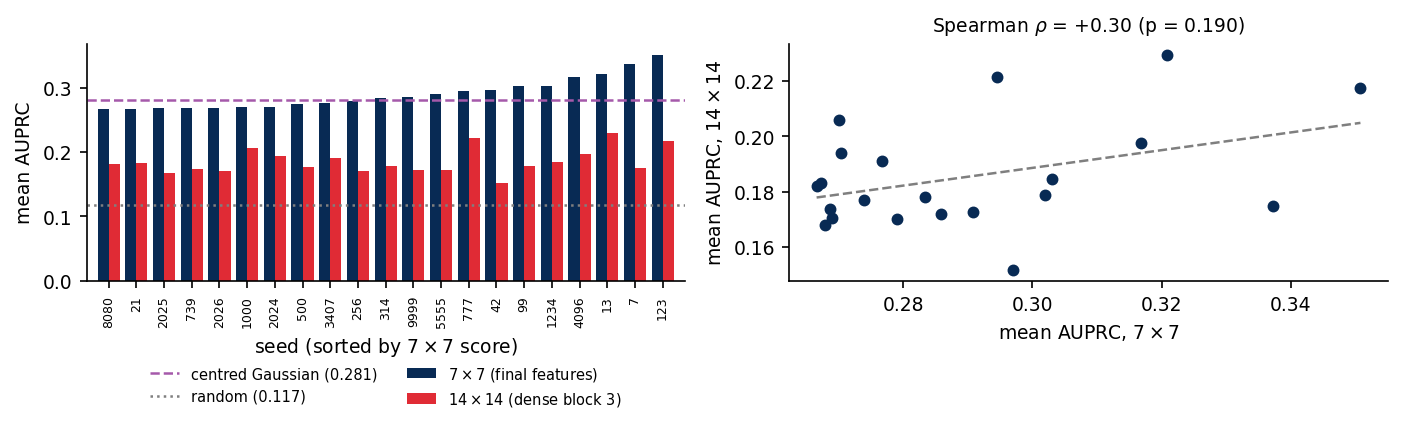

saved -> /content/drive/MyDrive/AI_Research/Model_Results/SaliencyRun/xrv_pipeline_nb/paper_outputs/F6_resolution.pdf

Caption:
  Grad-CAM at two feature resolutions, on the same 21 epoch-25 checkpoints and the same 601 images. Left: per-seed mean AUPRC at each grid, seeds ordered by the $7\times7$ score. Right: the same per-seed means against each other; the rank correlation between layers is Spearman $\rho = 0.30$ ($p = 0.190$)


In [13]:
#B1-B (F6)
import matplotlib.pyplot as plt

plt.rcParams.update({"font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 150})

C7, C14 = "#082a54", "#e02b35"
CENTRE_B = json.load(open(os.path.join(AGG_7, "summary.json")))["baseline_centre_gaussian"]

order = a7["per_seed"].sort_values().index
v7, v14 = a7["per_seed"].loc[order].values, a14["per_seed"].loc[order].values
x, w = np.arange(len(order)), 0.40

fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.2))

ax[0].bar(x - w / 2, v7,  w, color=C7,  label=r"$7\times7$ (final features)")
ax[0].bar(x + w / 2, v14, w, color=C14, label=r"$14\times14$ (dense block 3)")
ax[0].axhline(CENTRE_B, color="#a559aa", ls="--", lw=1.2,
              label=f"centred Gaussian ({CENTRE_B:.3f})")
ax[0].axhline(FLOOR, color="#7f7f7f", ls=":", lw=1.2, label=f"random ({FLOOR:.3f})")
ax[0].set_xticks(x)
ax[0].set_xticklabels(order, rotation=90, fontsize=6)
ax[0].set_xlabel("seed (sorted by $7\\times7$ score)")
ax[0].set_ylabel("mean AUPRC")
ax[0].legend(fontsize=7, frameon=False, ncol=2,
             loc="upper center", bbox_to_anchor=(0.5, -0.30))
ax[0].set_xlim(-0.8, len(order) - 0.2)

ax[1].scatter(a7["per_seed"].values, a14["per_seed"].values,
              s=22, color=C7, zorder=3)
ax[1].plot(np.sort(a7["per_seed"].values),
           np.poly1d(np.polyfit(a7["per_seed"].values, a14["per_seed"].values, 1))(
               np.sort(a7["per_seed"].values)),
           color="#7f7f7f", ls="--", lw=1.2, zorder=2)
ax[1].set_xlabel(r"mean AUPRC, $7\times7$")
ax[1].set_ylabel(r"mean AUPRC, $14\times14$")
ax[1].set_title(f"Spearman $\\rho$ = {rho:+.2f} (p = {rho_p:.3f})", fontsize=9)

plt.tight_layout()
plt.savefig(os.path.join(OUT, "F6_resolution.pdf"), bbox_inches="tight")
plt.show()

print(f"saved -> {OUT}/F6_resolution.pdf")
print("\nCaption:")
print(f"  Grad-CAM at two feature resolutions, on the same {a7['n_seeds']} "
      f"epoch-25 checkpoints and the same {a7['n_img']} images. Left: per-seed "
      f"mean AUPRC at each grid, seeds ordered by the $7\\times7$ score. Right: "
      f"the same per-seed means against each other; the rank correlation "
      f"between layers is Spearman $\\rho = {rho:.2f}$ ($p = {rho_p:.3f}$)")

B2: Seeds Curve (F7) & (T3)

full-sample SD (21 seeds) = 0.0243   200,000 draws per k

 k  median   lo95   hi95  within_tol  understate_factor
 2  0.0153 0.0007 0.0571      0.2156            35.4536
 3  0.0185 0.0020 0.0452      0.2814            12.0076
 4  0.0218 0.0049 0.0400      0.3256             4.9106
 5  0.0221 0.0072 0.0370      0.4276             3.3857
 6  0.0233 0.0091 0.0354      0.5043             2.6671
 7  0.0244 0.0104 0.0343      0.5989             2.3411
 8  0.0244 0.0114 0.0331      0.6552             2.1331
 9  0.0247 0.0121 0.0320      0.6975             2.0009
10  0.0247 0.0128 0.0310      0.7634             1.8953
11  0.0246 0.0136 0.0302      0.8339             1.7890
12  0.0246 0.0151 0.0295      0.8835             1.6045
13  0.0246 0.0157 0.0288      0.9124             1.5451
14  0.0247 0.0160 0.0282      0.9295             1.5166
15  0.0249 0.0166 0.0277      0.9433             1.4670
16  0.0251 0.0176 0.0271      0.9565             1.3796
17  0.0251 0.0179 0.0266      0.9713          

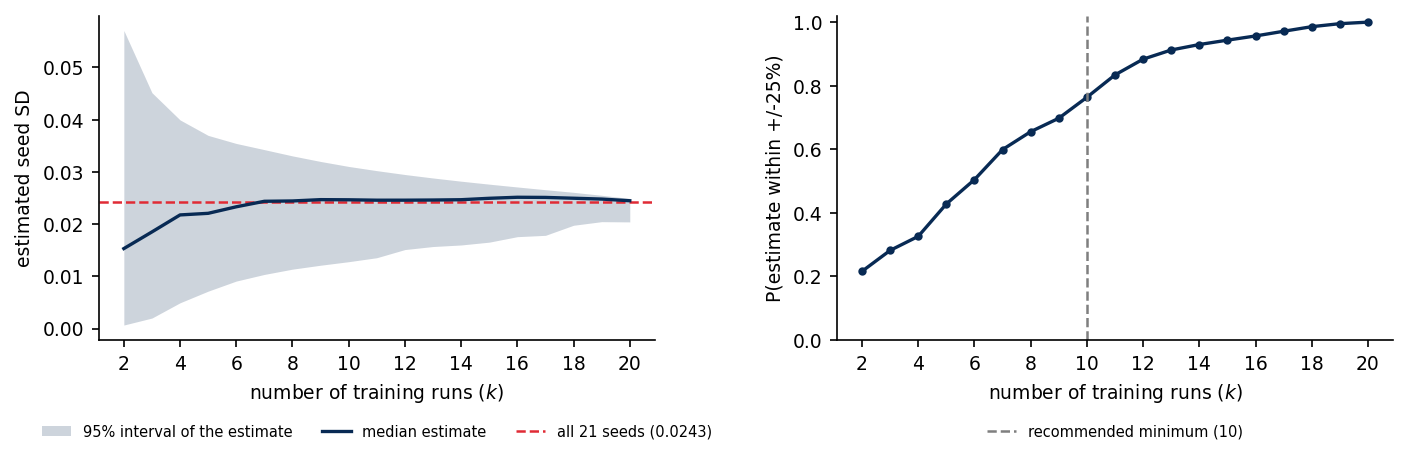


saved -> /content/drive/MyDrive/AI_Research/Model_Results/SaliencyRun/xrv_pipeline_nb/paper_outputs/F7_seeds.pdf and T3_seeds.csv


In [14]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

AGG_7 = os.path.join(XRV_SAVE_DIR, "gradcam_metrics_25_withGBP", "_aggregate")
OUT   = os.path.join(XRV_SAVE_DIR, "paper_outputs")
os.makedirs(OUT, exist_ok=True)

N_DRAW  = 200000         # draws per k
TOL     = 0.25           # "within +/-25% of the full-sample value"
K_RANGE = range(2, 21)
rng = np.random.default_rng(42)

per_seed = (pd.read_csv(os.path.join(AGG_7, "per_seed_summary.csv"))
            .sort_values("seed").auprc_mean.values)
N      = len(per_seed)
SD_ALL = per_seed.std(ddof=1)

rows = []
for k in K_RANGE:
    s = np.array([rng.choice(per_seed, k, replace=False).std(ddof=1)
                  for _ in range(N_DRAW)])
    lo, hi = np.percentile(s, [2.5, 97.5])
    rows.append({"k": k, "median": np.median(s), "lo95": lo, "hi95": hi,
                 "within_tol": float((np.abs(s - SD_ALL) / SD_ALL < TOL).mean()),
                 "understate_factor": SD_ALL / lo})
cur = pd.DataFrame(rows)

print(f"full-sample SD ({N} seeds) = {SD_ALL:.4f}   {N_DRAW:,} draws per k\n")
print(cur.round(4).to_string(index=False))
cur.to_csv(os.path.join(OUT, "T3_seeds_needed.csv"), index=False)

for k in (5, 10):
    r = cur[cur.k == k].iloc[0]
    print(f"\n  k = {k:>2}: SD {r.lo95:.3f} to {r.hi95:.3f}, "
          f"within {TOL:.0%} in {r.within_tol:.0%} of draws, "
          f"understates by up to {r.understate_factor:.1f}x")

plt.rcParams.update({"font.size": 9, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 150})
BLUE, RED, GRAY = "#082a54", "#e02b35", "#7f7f7f"

fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.2))

ax[0].fill_between(cur.k, cur.lo95, cur.hi95, color=BLUE, alpha=.2, lw=0,
                   zorder=0,
                   label="95% interval of the estimate")
ax[0].plot(cur.k, cur["median"], color=BLUE, lw=1.6, zorder=3,
           label="median estimate")
ax[0].axhline(SD_ALL, color=RED, ls="--", lw=1.2, zorder=2,
              label=f"all {N} seeds ({SD_ALL:.4f})")
ax[0].set_xlabel("number of training runs ($k$)")
ax[0].set_ylabel("estimated seed SD")
ax[0].set_xticks(list(K_RANGE)[::2])
ax[0].legend(fontsize=7, frameon=False, ncol=3,
             loc="upper center", bbox_to_anchor=(0.5, -0.22))

ax[1].plot(cur.k, cur.within_tol, color=BLUE, lw=1.6, marker="o", ms=3)
ax[1].axvline(10, color=GRAY, ls="--", lw=1.2, label="recommended minimum (10)")
ax[1].set_xlabel("number of training runs ($k$)")
ax[1].set_ylabel(f"P(estimate within +/-{TOL:.0%})")
ax[1].set_ylim(0, 1.02)
ax[1].set_xticks(list(K_RANGE)[::2])
ax[1].legend(fontsize=7, frameon=False, ncol=1,
             loc="upper center", bbox_to_anchor=(0.5, -0.22))

plt.tight_layout()
plt.savefig(os.path.join(OUT, "F7_seeds.pdf"), bbox_inches="tight")
plt.show()

print(f"\nsaved -> {OUT}/F7_seeds.pdf and T3_seeds.csv")